# GEMS — Phase 3: Calibration, spatial generalisation and fault discovery

| | question | section | headline output |
|---|---|---|---|
| RQ1 | Are calibration and rank-ensemble gains real or validation artifacts? | 1, 2, 8 | `calibration_audit.csv`, `transform_comparison.csv`, `tables/rank_ensemble_decomposition.csv` |
| RQ2 | Why do LightGBM models stop so early? | 4 | `lgbm_diagnostics.csv` |
| RQ3 | Which models recover best at comparable predicted-area budgets? | 3 | `matched_budget_comparison.csv`, `recall_area_curves.csv` |
| RQ4 | Can spatial CNNs improve localisation and short-fault recovery? | 6 | `cnn_benchmark.csv` |
| RQ5 | Which modalities contribute unique information? | 5 | `modality_ablation.csv` |
| RQ6 | Can withheld systems be recovered without flooding the map? | 3, 6, 8 | `pseudo_discovery_comparison.csv`, `ensemble_validation.csv` |

**Key idea used throughout.** For a fixed truth set the DTI is maximised by a *binary* map (proof sketch in `gems_bench/p3/curves.py`, brute-force test in `tests/test_phase3_scoring.py`). Models are therefore compared by their *ranking* cut at the same predicted-area budget (binary top-a mask per held-out fold), with the budget chosen on the other folds. Probability calibration in the ML sense does not change the score.

**Leakage rules.** Every transform parameter, area budget, ensemble weight and fusion fit is selected on folds other than the scored one. Per-fold quantiles are label-free. Pseudo-discovery withheld systems are never negatives (weight 0) in any model.

**How to run.** Top to bottom; every expensive step is cached and skipped when done (`OVERWRITE=False`). Priorities: sections 1-3 (P0, no training) -> 4-6 (P1) -> 7-8 (P2). Dependencies: `pip install -r requirements-phase3.txt` (+ CUDA torch for section 6). Outputs: `outputs/phase3/` (reload paths in `outputs/phase3/manifest.json`, run index in `experiment_registry.csv` and `experiment_manifest.csv`).

## 0 · Setup — reload Phase-1/2 artifacts (no recomputation)

In [1]:
import sys, json, time, subprocess, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'gems-geodawn-numerical-features.tif').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from gems_bench import geo_eval
from gems_bench.ensemble import read_map
from gems_bench.p3 import load_context
from gems_bench.p3 import audit, budget, curves, discovery3, ensemble3, lgbm3, lineaments, report3, transforms
from gems_bench.p3.context import write_experiment_manifest

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice')
pd.set_option('display.width', 220, 'display.max_columns', 40)

# ---- run switches (P0: 3A, 3B | P1: 3C, 3D, 3E | P2: 3F, 3G) ----
RUN_3A = False          # calibration + scoring audit (reuses Phase-2 OOF maps, no training)
RUN_3B = False          # recall-area-DTI + corrected pseudo-discovery (no training)
RUN_3C = False          # LightGBM diagnostics grid (10 CV runs + 15 discovery fits, CPU)
RUN_3D = False          # G3 modality ablation (6 CV runs + 18 discovery fits, CPU)
RUN_3E = True          # U-Net benchmark (torch; GPU strongly recommended)
RUN_3F = True          # candidate lineaments (interpretation only)
RUN_3G = True          # nested ensemble validation
RUN_SUBMISSION = False # leaderboard probe files (written, never uploaded)
OVERWRITE = False

# ---- experiment settings (persisted in each run's config.json) ----
MATCH_FRAC = 0.05                       # matched area budget for per-system / per-segment tables
TF_FAMILIES = transforms.ALL_FAMILIES
LGBM_SELECT = list(lgbm3.LGBM_GRID)
LGBM_DISC_SELECT = ['D0_p2_replica', 'D2_conservative', 'D3_conservative_lr', 'D5_conservative_S2', 'F2_fixed400_C2']
ABLATION_BASE = 'D0_p2_replica'         # switch to a 3C winner only if its rule in PHASE3_FINDINGS passes
ABL_TOPK = 15
CNN_SELECT = ['CNN_A_bcedice', 'CNN_A_dti', 'CNN_B_bcedice']
CNN_DISC_SELECT = ['CNN_A_bcedice']
LIN_TOP_FRAC, LIN_SCALES = 0.05, (300.0, 600.0)

ctx = load_context(ROOT)
CFG, OUT = ctx.cfg, ctx.paths.out
RNG = np.random.default_rng(CFG.seed)
ZOO = ctx.available_oof()
ALL_MAPS = {m: ctx.oof(m) for m in ZOO}            # name -> raw OOF map; grows with Phase-3 runs
EXP_ROWS = []                                       # experiment manifest rows
G3_NAMES = json.loads((ctx.phase2_run('G3').dir / 'config.json').read_text())['features']
FOLDS_REL = ctx.bench.rel(ctx.folds.directory)

def show(fig, name, desc='', where=None):
    ctx.save_fig(fig, name, desc, where=where)
    plt.show()

def save(df, name, desc='', headline=False):
    return ctx.save_table(df, name, desc, where=OUT if headline else None)

def manifest_row(exp_id, section, kind, params, features, run_dir):
    EXP_ROWS.append({'exp_id': exp_id, 'section': section, 'kind': kind, 'params': params, 'features': features,
                     'folds': FOLDS_REL, 'seed': CFG.seed, 'artifacts': ctx.paths.rel(run_dir)})

print('root:', ROOT, '| outputs:', OUT)
print('model zoo:', ZOO, '| G3 features:', len(G3_NAMES))
print('folds:', ctx.folds.n_folds, '| discovery splits:', ctx.splits.n_splits, '| segment raster:', ctx.seg is not None)

root: C:\Users\myben\Downloads\GEMS | outputs: C:\Users\myben\Downloads\GEMS\outputs\phase3
model zoo: ['B0_lineament', 'B0_terrain', 'G1', 'G2', 'G3', 'G4', 'ens_mean', 'ens_rank_mean', 'ens_weighted'] | G3 features: 52
folds: 3 | discovery splits: 3 | segment raster: True


## 1 · Phase 3A — calibration integrity audit (RQ1)

`calibration_audit.csv` combines **code findings** (established by reading the Phase-2 implementation; file:line evidence) with **data checks** on the saved artifacts. Questions covered: which pixels and labels fit the transforms, whether held-out labels choose their own transform, whether families were chosen on the reported folds, invalid-pixel contamination, ties, global vs regional ranks, exclusion masks, and OOF-vs-submission transform consistency.

Then every model is re-scored under the **same** transform families (raw, linear, temperature, isotonic, Phase-2 power-floor, extended power-floor, Phase-2 rank grid, per-fold rank, soft threshold, hard threshold), each selected on the other folds. Phase-2 `transform_grid.csv` tables are reused for the power-floor family.

In [2]:
if RUN_3A:
    FULL_MAPS = {m: ctx.bench.submissions / 'full_maps' / f'lgbm_{m}_s{CFG.seed}.tif' for m in ('G2', 'G3', 'G4')}
    names = [m for m in ('G1', 'G2', 'G3', 'G4', 'B0_lineament', 'B0_terrain', 'ens_rank_mean') if m in ZOO]
    AUDIT = pd.concat([audit.code_audit_table(),
                       audit.run_data_checks(ctx, names, {k: str(v) for k, v in FULL_MAPS.items()})], ignore_index=True)
    save(AUDIT, 'calibration_audit', 'Code findings + data checks: calibration, ranking, masks, submission, discovery', headline=True)
    display(AUDIT[['check_id', 'kind', 'area', 'status', 'finding']])
    display(AUDIT[AUDIT.kind == 'data'][['check_id', 'status', 'finding', 'value']])

In [3]:
if RUN_3A:
    SCORERS = transforms.FoldScorers(ctx.data.labels, ctx.folds.fold_map, ctx.data.valid)
    TF_MODELS = [m for m in ('G3', 'G1', 'G4', 'B0_lineament', 'ens_rank_mean') if m in ZOO]
    tabs = []
    for m in TF_MODELS:
        cache = ctx.paths.tables / f'transform_table_{m}.parquet'
        if cache.exists() and not OVERWRITE:
            tabs.append(pd.read_parquet(cache))
            continue
        grid_csv = ctx.phase2_run(m).dir / 'transform_grid.csv' if m in ('G1', 'G2', 'G3', 'G4') else None
        reuse = pd.read_csv(grid_csv) if grid_csv is not None and grid_csv.exists() else None
        t0 = time.time()
        t = transforms.family_table(m, ALL_MAPS[m], ctx.data.labels, ctx.folds.fold_map, ctx.data.valid, SCORERS,
                                    families=TF_FAMILIES, rng=RNG, reuse_p2_grid=reuse)
        t.to_parquet(cache, index=False)
        print(f'{m}: {len(t)} rows in {time.time() - t0:.0f} s')
        tabs.append(t)
    TF_TABLE = pd.concat(tabs, ignore_index=True)
    TF_COMP, TF_PER = transforms.compare_families(TF_TABLE)
    save(TF_COMP, 'transform_comparison', 'Cross-fitted DTI per transform family and model (+ optimism, grid-edge flag)', headline=True)
    save(TF_PER, 'transform_crossfit_choices', 'Per-fold transform parameter chosen on the other folds')
    display(TF_COMP.pivot_table(index='family', columns='model', values='dti_crossfit').round(4))
    display(TF_COMP[['model', 'family', 'dti_crossfit', 'dti_insample', 'optimism', 'fold_min', 'fold_max',
                     'choice_on_grid_edge']].round(4))
    show(report3.fig_family_comparison(TF_COMP), 'calibration_diagnostics', 'Transform families: cross-fitted DTI and fold range', where=OUT)
    show(report3.fig_calibration_curves(ctx, TF_MODELS), 'calibration_curves', 'Reliability of raw OOF maps', where=OUT)
    full = {m: read_map(p) for m, p in FULL_MAPS.items() if p.exists()}
    show(report3.fig_prediction_distributions(ctx, [m for m in ('G1', 'G3', 'G4') if m in ZOO], full),
         'prediction_distributions', 'OOF quantile functions per fold vs full-region submission map', where=OUT)
    audit.write_calibration_findings(OUT / 'calibration_findings.md', AUDIT, TF_COMP)
    ctx.manifest.add('calibration_findings', OUT / 'calibration_findings.md', 'report', 'Phase 3A calibration findings')
    display(Markdown((OUT / 'calibration_findings.md').read_text(encoding='utf-8')))

## 2 · Exact scoring and exclusion-mask audit

`tests/test_phase3_scoring.py` checks the DTI implementation against analytic values: 1/2/3-px displacement (DTI = 1 - s/3), width expansion (30/34, 30/42), parallel predictions, soft k(d) corridors, exact known-fault exclusion, the three withheld-system policies, valid masking / NaN, pooled vs regional aggregation, the all-threshold binary engine against `MaskedScorer`, and binary optimality by brute force. The cell below runs them together with the Phase-2 metric tests and saves the log.

In [4]:
res = subprocess.run([sys.executable, '-m', 'pytest', 'tests/test_phase3_scoring.py', 'tests/test_metric.py', '-q'],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout[-4000:])
print(res.stderr[-2000:])
(OUT / 'scoring_tests_output.txt').write_text(res.stdout + res.stderr, encoding='utf-8')
save(audit.METRIC_CORRESPONDENCE, 'metric_correspondence', 'Which local metric corresponds to which competition scenario', headline=True)
display(audit.METRIC_CORRESPONDENCE)

........................................                                 [100%]
============================== warnings summary ===============================
tests/test_phase3_scoring.py::test_zone_curves_and_crossfit
tests/test_phase3_scoring.py::test_zone_curves_and_crossfit
tests/test_phase3_scoring.py::test_zone_curves_and_crossfit
  C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:241: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
    other = table[table[zone_col] != z].groupby(params).apply(dti_from).rename("dti_other").reset_index()

tests/test_phase3_scoring.py::test_zone_curves_and_crossfit
  C:\Users\myben\Downloads\GEMS\gems_bench\p3\curves.py:251: FutureWarning: DataFrameGroupBy.apply

,local_metric,truth,known_faults,closest_to,use
0,"geographic pooled DTI, binary top-a mask, cros...",all mapped faults in held-out folds,truth,reproducing the USGS map in unseen regions,model ranking / localisation quality; NOT the ...
1,"pseudo-discovery DTI, retained faults counted ...",withheld systems only,predictions on them are FP,leaderboard IF known faults are not excluded f...,primary proxy for new-fault scoring under poli...
2,"pseudo-discovery DTI, retained faults excluded...",withheld systems only,neither TP nor FP,leaderboard IF the organisers exclude known fa...,secondary proxy
3,"pseudo-discovery DTI, all faults truth (Phase-...",withheld + retained,truth,nothing in the competition,sanity only
4,density-adjusted DTI (budget.density_sensitivity),mapped faults thinned to rho x density,-,operating-point choice when hidden truth is sp...,choose the area budget of leaderboard probes


## 3 · Phase 3B — recall-area-DTI at matched budgets (RQ3, RQ6)

Every saved OOF map is cut into binary top-a masks per held-out fold (`per_zone`) and, for reference, at one global threshold (`global`). For each area fraction: DTI, distance-weighted recall, recall@100/200/300 m, area, FP mass, area > 1 km from mapped faults. The area budget is cross-fitted (chosen on two folds, scored on the third). High recall is only compared at equal area.

Pseudo-discovery is re-scored from the saved Phase-2 discovery predictions (no retraining) with exact pixel weights, three known-fault policies (`excl`, `retained_fp`, `all_truth`) and a `suppress_known` prediction variant.

In [5]:
if RUN_3B:
    B_MODELS = [m for m in ('G1', 'G2', 'G3', 'G4', 'B0_lineament', 'B0_terrain', 'ens_mean', 'ens_rank_mean', 'ens_weighted') if m in ZOO]
    f = OUT / 'recall_area_curves.csv'
    if f.exists() and not OVERWRITE:
        GEO = pd.read_csv(f)
    else:
        GEO = budget.geo_curves(ctx, B_MODELS, modes=('per_zone', 'global'), maps=ALL_MAPS)
        save(GEO, 'recall_area_curves', 'Per-fold binary-mask DTI / recall / area / FP mass per model and area fraction', headline=True)
    GEO_POOL = budget.pool_models(GEO)
    save(GEO_POOL, 'recall_area_pooled', 'Pooled-over-folds recall-area-DTI per model, mode and area fraction')
    AREA_CF = budget.crossfit_area(GEO)
    save(AREA_CF, 'crossfit_area_by_model', 'Binary-mask DTI with the area fraction cross-fitted over geographic folds')
    display(AREA_CF.sort_values('dti_crossfit_area', ascending=False).round(4))
    MATCHED = budget.matched_budget_table(GEO_POOL)
    save(MATCHED, 'matched_budget_comparison', 'Models at matched predicted-area budgets (pooled over folds)', headline=True)
    display(MATCHED.pivot_table(index='model', columns='target_frac', values='dti').round(4))
    display(MATCHED.pivot_table(index='model', columns='target_frac', values='recall@300m').round(3))
    if 'G3' in B_MODELS and 'G1' in B_MODELS:
        OPR = budget.pairwise_operating_range(GEO, 'G3', 'G1')
        save(OPR, 'operating_range_G3_vs_G1', 'DTI / recall differences G3 - G1 per area fraction and fold')
        display(OPR.round(4))
    DENS = budget.density_sensitivity(GEO_POOL)
    save(DENS.drop(columns='dti_at_frac'), 'density_sensitivity', 'Optimal area budget if hidden truth were rho x USGS density')
    display(DENS.pivot_table(index='model', columns='rho', values='best_frac'))
    FRONT = budget.pareto_front(GEO_POOL[GEO_POOL['mode'] == 'per_zone'])
    save(FRONT, 'pareto_front', 'Recovery vs false-positive mass, Pareto flags over all models and budgets')
    show(budget.fig_budget_curves(GEO_POOL, GEO), 'recall_area_dti_curves', 'Recall / DTI vs predicted area, pooled and per fold')
    show(budget.fig_matched_bars(MATCHED), 'matched_budget_bars', 'DTI at matched area budgets')
    show(budget.fig_pareto(FRONT), 'recall_area_pareto', 'Recovery vs FP mass with Pareto front', where=OUT)
    if RUN_3A:
        show(budget.fig_dti_vs_scale(TF_TABLE), 'dti_vs_confidence_scale', 'DTI vs linear probability scale')

In [6]:
if RUN_3B:
    # (a) Phase-2 scoring, now with exact n_px weights (P0 item 5)
    P2SUM, P2SENS = discovery3.phase2_sensitivity_exact(ctx, ('G1', 'G2', 'G3', 'B0_lineament'))
    save(P2SENS, 'pseudo_discovery_sensitivity_exact', 'Phase-2 discovery scoring re-weighted by exact withheld pixel counts')
    display(P2SENS.pivot_table(index=['stratum', 'value'], columns='model', values='weighted_recall').round(3))
    # (b) matched-budget re-scoring with three known-fault policies
    D_MODELS = ['G1', 'G2', 'G3', 'B0_lineament']
    DCURVES, DOBJ = discovery3.discovery_curves(ctx, D_MODELS)
    save(DCURVES, 'pseudo_discovery_curves', 'Binary-mask curves in the evaluation zone per split, policy and variant')
    DSUM = discovery3.discovery_summary(DCURVES)
    save(DSUM, 'pseudo_discovery_comparison', 'Pseudo-discovery at matched budgets + cross-fitted area (3 policies, 2 variants)', headline=True)
    display(DSUM[DSUM.row == 'crossfit_area'].pivot_table(index=['model', 'variant'], columns='policy', values='dti').round(4))
    m = (DSUM.row == 'matched_budget') & (DSUM.policy == 'excl') & (DSUM.variant == 'model')
    display(DSUM[m].pivot_table(index='model', columns='target_frac', values='recall@300m').round(3))
    # (c) per withheld system at a matched budget; systems only G1 recovers
    DSYS = discovery3.systems_at_budget(ctx, DOBJ, MATCH_FRAC)
    save(DSYS, 'pseudo_discovery_by_system_matched', 'Per withheld system recall at the matched budget (exact n_px)')
    DSENS = discovery3.sensitivity_exact(DSYS)
    save(DSENS, 'pseudo_discovery_sensitivity_matched', 'Withheld recall by length / region at the matched budget')
    display(DSENS.pivot_table(index=['stratum', 'value'], columns='model', values='weighted_recall').round(3))
    UNIQ = discovery3.unique_recoveries(DSYS, 'G1', 'G3')
    save(UNIQ, 'discovery_unique_G1_vs_G3', 'Systems recovered by G1 (>= 0.5) and missed by G3 by >= 0.3 at the same budget')
    print('systems uniquely recovered by G1 at the matched budget:', len(UNIQ))
    sel = DCURVES[(DCURVES.policy == 'retained_fp') & (DCURVES.variant == 'model')].assign(mode='per_zone')
    show(budget.fig_budget_curves(budget.pool_models(sel), sel), 'discovery_recall_area_curves',
         'Pseudo-discovery (retained faults = FP): recall / DTI vs share of the evaluation zone')

In [7]:
if RUN_3B and ctx.seg is not None:
    SEGREC = budget.segment_recall_at_budget(ctx, {m: ALL_MAPS[m] for m in ('G1', 'G3', 'B0_lineament') if m in ALL_MAPS}, MATCH_FRAC)
    rows = []
    for m, r in SEGREC.items():
        s = geo_eval.stratified_recall(r, ['length_bin', 'region_name', 'fold', 'primary_archetype'])
        s.insert(0, 'model', m)
        rows.append(s)
    SEGSTRAT = pd.concat(rows, ignore_index=True)
    save(SEGSTRAT, 'segment_recall_matched_budget', 'Mapped-segment recall by length / region / fold / archetype at the matched budget')
    display(SEGSTRAT[SEGSTRAT.stratum == 'length_bin'].pivot_table(index='value', columns='model', values='recall@300m').round(3))
    display(SEGSTRAT[SEGSTRAT.stratum == 'region_name'].pivot_table(index='value', columns='model', values='recall@300m').round(3))
    _, OVER = geo_eval.recovery_overlap(SEGREC)
    save(OVER, 'segment_recovery_overlap_matched', 'Recovered trace km both / only-a / only-b at the matched budget')
    display(OVER.round(1))

## 4 · Phase 3C — LightGBM early-stopping diagnostics (RQ2)

First the Phase-2 histories are parsed (no training): where inner-validation logloss and AUC peak, and how much AUC is gained after the first tree. Then a compact controlled grid on G3 features, same folds / seed / sampler: two learning rates (0.05, 0.01), two tree complexities (C1 = Phase-2, C2 = 15 leaves, 2000 min-child, strong L2, 50 % feature/row sampling), two sampling schemes (S1 = Phase-2 positives + ring + uniform; S2 = thinned positives + uniform only), early stopping on AUC (`first_metric_only`) vs Phase-2 any-metric, and fixed-round baselines (100 / 400). Each run reports the scale-free cross-fitted area DTI, prediction spread, area far from labels and, for five configs, pseudo-discovery.

In [8]:
if RUN_3C:
    HIST = lgbm3.history_diagnostics(ctx)
    save(HIST, 'lgbm_history_diagnostics', 'Phase-2 LightGBM histories: inner-val peaks, AUC gain after tree 1, generalisation gap')
    display(HIST.round(3))
    LGBM_RUNS = {}
    for key in LGBM_SELECT:
        v = lgbm3.LGBM_GRID[key]
        exp = f'p3_lgbm_{key}_G3_s{CFG.seed}'
        LGBM_RUNS[key] = lgbm3.run_variant_cv(ctx, exp, G3_NAMES, v, overwrite=OVERWRITE, tag='3C')
        ALL_MAPS[key] = ctx.oof(exp)
        manifest_row(exp, '3C', 'lgbm_cv', v, 'G3', LGBM_RUNS[key].dir)
    for key in [k for k in LGBM_DISC_SELECT if k in LGBM_RUNS]:
        v, run = lgbm3.LGBM_GRID[key], LGBM_RUNS[key]
        rounds = max(1, int(np.median(run.state['summary']['best_iters'])))
        for d in range(ctx.splits.n_splits):
            lgbm3.fit_full_variant(ctx, f'disc{d}_{key}', G3_NAMES, v, rounds, ignore_mask=ctx.splits.ignore(d),
                                   predict_area=ctx.splits.eval_zone(d) & ctx.data.valid, overwrite=OVERWRITE)
            manifest_row(f'disc{d}_{key}', '3C', 'lgbm_discovery', {**v, 'rounds': rounds, 'split': d}, 'G3',
                         ctx.paths.experiments / f'disc{d}_{key}')
    LDC, _ = discovery3.discovery_curves(ctx, [k for k in LGBM_DISC_SELECT if k in LGBM_RUNS],
                                         policies=('excl', 'retained_fp'), variants=('model',))
    LDS = discovery3.discovery_summary(LDC)
    lgc = budget.geo_curves(ctx, list(LGBM_RUNS), maps={k: ALL_MAPS[k] for k in LGBM_RUNS})
    lcf = budget.crossfit_area(lgc).set_index('model')
    lpool = budget.pool_models(lgc)
    ldisc = LDS[LDS.row == 'crossfit_area'].pivot_table(index='model', columns='policy', values='dti')
    rows = []
    for key, run in LGBM_RUNS.items():
        s = run.state['summary']
        q = run.table('prediction_quantiles')
        q = q[q.part == 'all']
        mf = run.table('metrics_fold')
        mf = mf[mf.fold != 'pooled']
        at = lpool[(lpool.model == key) & (lpool.target_frac == MATCH_FRAC)].iloc[0]
        row = {'config': key, **lgbm3.LGBM_GRID[key], 'best_iters': s['best_iters'],
               'dti_crossfit_area': lcf.loc[key, 'dti_crossfit_area'], 'fold_min': lcf.loc[key, 'fold_min'],
               'fold_max': lcf.loc[key, 'fold_max'], 'dti_raw_pooled': s['dti_pooled_raw'], 'roc_auc_pooled': s['roc_auc_pooled'],
               'recall300_at_match': at['recall@300m'], 'far_share_at_match': at['far_area_km2'] / max(at['area_km2'], 1e-9),
               'pred_q99_minus_q50': float((q['q0.99'] - q['q0.5']).mean()), 'train_seconds': s['train_seconds']}
        for c in ('inner_auc_iter1', 'inner_auc_best', 'best_iter_auc', 'best_iter_binary_logloss'):
            row[c] = float(pd.to_numeric(mf[c], errors='coerce').mean()) if c in mf else np.nan
        for pol in ('excl', 'retained_fp'):
            row['disc_dti_' + pol] = ldisc.loc[key, pol] if key in ldisc.index else np.nan
        rows.append(row)
    LGBM_DIAG = pd.DataFrame(rows)
    save(LGBM_DIAG, 'lgbm_diagnostics', 'Controlled LightGBM grid: area DTI, folds, spread, iterations, discovery', headline=True)
    display(LGBM_DIAG.round(4))
    keys = list(LGBM_RUNS)
    ncol = 5
    nrow = int(np.ceil(len(keys) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.0 * nrow), squeeze=False, constrained_layout=True)
    for ax, key in zip(axs.ravel(), keys):
        h = LGBM_RUNS[key].table('history')
        h = h[(h.stage == 'inner') & (h.metric == 'auc')]
        for (split, fo), g in h.groupby(['split', 'fold']):
            iv = split == 'inner_val'
            ax.plot(g.iteration, g.value, lw=1.2, color='#2a78d6' if iv else '#8a8985', alpha=0.9 if iv else 0.6)
        ax.set_xscale('log')
        ax.set_title(key, fontsize=9, loc='left')
        ax.tick_params(labelsize=7)
    for ax in axs.ravel()[len(keys):]:
        ax.axis('off')
    fig.suptitle('AUC vs boosting round (blue = inner validation per fold, grey = train)', fontsize=10)
    show(fig, 'lgbm_training_curves', 'Train vs inner-validation AUC per config and fold')

## 5 · Phase 3D — G3 modality ablation (RQ5)

A0 full G3 · A1 minus terrain · A2 minus magnetic · A3 minus gravity and basement · A4 minus seismicity and strain · A5 top-15 features. Same folds, sampler, seed and LightGBM config (`ABLATION_BASE`). A5 is label-safe: for geographic fold k the subset comes from the A0 fold-k model (trained without fold k); for discovery split d from the A0 discovery model of split d (trained with the withheld systems ignored). Reported: spatial and pseudo-discovery DTI, recall by fault length and region, Jaccard agreement with A0, and confidence away from mapped faults. A modality is never dropped on SHAP magnitude alone.

In [9]:
if RUN_3D:
    vb = lgbm3.LGBM_GRID[ABLATION_BASE]
    ABL = {}
    for key, drop in lgbm3.ABLATIONS.items():
        exp = f'p3_abl_{key}_{ABLATION_BASE}_s{CFG.seed}'
        if drop == 'top':
            tops = lgbm3.top_features_per_fold(ABL['A0_full'], ABL_TOPK)
            union = sorted(set(sum(tops.values(), [])))
            ABL[key] = lgbm3.run_variant_cv(ctx, exp, union, vb, names_per_fold=tops, overwrite=OVERWRITE, tag='3D')
        else:
            ABL[key] = lgbm3.run_variant_cv(ctx, exp, lgbm3.ablation_features(ctx, G3_NAMES, drop), vb,
                                            overwrite=OVERWRITE, tag='3D')
        ALL_MAPS[key] = ctx.oof(exp)
        manifest_row(exp, '3D', 'ablation_cv', {**vb, 'drop': str(drop)}, len(ABL[key].config['features']), ABL[key].dir)
    r0 = max(1, int(np.median(ABL['A0_full'].state['summary']['best_iters'])))
    for d in range(ctx.splits.n_splits):
        ign, zone = ctx.splits.ignore(d), ctx.splits.eval_zone(d) & ctx.data.valid
        _, gain0 = lgbm3.fit_full_variant(ctx, f'disc{d}_abl_A0_full', G3_NAMES, vb, r0, ignore_mask=ign,
                                          predict_area=zone, overwrite=OVERWRITE)
        for key, run in ABL.items():
            if key == 'A0_full':
                continue
            nm = lgbm3.top_features_from_gain(gain0, ABL_TOPK) if key == 'A5_top_features' else run.config['features']
            rounds = max(1, int(np.median(run.state['summary']['best_iters'])))
            lgbm3.fit_full_variant(ctx, f'disc{d}_abl_{key}', nm, vb, rounds, ignore_mask=ign, predict_area=zone,
                                   overwrite=OVERWRITE)
    abl_maps = {k: ALL_MAPS[k] for k in ABL}
    AGC = budget.geo_curves(ctx, list(abl_maps), maps=abl_maps)
    ACF = budget.crossfit_area(AGC).set_index('model')
    APOOL = budget.pool_models(AGC)
    ADC, _ = discovery3.discovery_curves(ctx, ['abl_' + k for k in ABL], policies=('excl', 'retained_fp'), variants=('model',))
    ADS = discovery3.discovery_summary(ADC)
    adcf = ADS[ADS.row == 'crossfit_area'].pivot_table(index='model', columns='policy', values='dti')
    SEGA = budget.segment_recall_at_budget(ctx, abl_maps, MATCH_FRAC) if ctx.seg is not None else {}
    far = ctx.dist_to_labels_km() > 2.0
    rows = []
    for k in ABL:
        at = APOOL[(APOOL.model == k) & (APOOL.target_frac == MATCH_FRAC)].iloc[0]
        row = {'ablation': k, 'dropped': str(lgbm3.ABLATIONS[k]), 'n_features': len(ABL[k].config['features']),
               'spatial_dti': ACF.loc[k, 'dti_crossfit_area'], 'spatial_fold_min': ACF.loc[k, 'fold_min'],
               'disc_dti_excl': adcf.loc['abl_' + k, 'excl'], 'disc_dti_retained_fp': adcf.loc['abl_' + k, 'retained_fp'],
               'recall300_at_match': at['recall@300m'], 'far_share_at_match': at['far_area_km2'] / max(at['area_km2'], 1e-9),
               'mean_p_far_from_labels': float(np.nanmean(abl_maps[k][ctx.data.valid & far])),
               'jaccard_top_vs_A0': lgbm3.jaccard_top(abl_maps[k], abl_maps['A0_full'], ctx.data.valid, ctx.folds.fold_map, MATCH_FRAC)}
        if k in SEGA:
            for r in geo_eval.stratified_recall(SEGA[k], ['length_bin', 'region_name']).to_dict('records'):
                row['recall300_' + r['stratum'] + '_' + r['value']] = r['recall@300m']
        rows.append(row)
    ABL_TABLE = pd.DataFrame(rows)
    base = ABL_TABLE.set_index('ablation').loc['A0_full']
    for c in ('spatial_dti', 'disc_dti_excl', 'disc_dti_retained_fp', 'recall300_at_match'):
        ABL_TABLE['delta_' + c] = ABL_TABLE[c] - base[c]
    save(ABL_TABLE, 'modality_ablation', 'G3 modality ablation: spatial + discovery DTI, recall strata, agreement, far confidence', headline=True)
    display(ABL_TABLE.round(4).T)

## 6 · Phase 3E — first real CNN benchmark (RQ4)

Built-in U-Net (no pretrained weights; smp optional), 256 px patches (25.6 km), 50 % fault-centred patches lying entirely inside the fold training zone, PU ignore band (1-2 px around visible labels, weight 0), rot180 augmentation, AdamW + one-cycle, mixed precision on CUDA, Hann-blended sliding-window inference at 50 % overlap, checkpoint and patience early stopping on inner-validation binary-area DTI (training-side labels). CNN-A = 19 raw bands; CNN-B = raw + 10 Phase-1-motivated engineered layers. Losses: BCE + Dice vs a differentiable DTI surrogate (`loss='dti'`). Pseudo-discovery: whole-map training with withheld systems + ring at weight 0, fixed epochs = median best CV epoch.

Requires the **CUDA build** of `torch`: a `+cpu` wheel makes this section take hours, so the cell below stops with the install command instead of silently training on the CPU (`CNN_REQUIRE_CUDA`). Install it in the GEMS env, e.g. `pip install --force-reinstall torch --index-url https://download.pytorch.org/whl/cu128` (any CUDA 12.x/13.x wheel your driver supports; pick yours at pytorch.org), then **restart the kernel**.

GPU throughput settings (`CNN_GPU`, objective unchanged): the normalised stack and targets stay resident on the GPU and patches are cut there; bf16 autocast (Ampere+) with channels_last; cuDNN autotuning + TF32 (`cudnn_benchmark=False` for bit-reproducible kernels); inner-val / OOF inference fully on the GPU in batches of `infer_batch` tiles. `eval_every=2` halves the inner-validation cost (patience then counts evaluations). Each epoch prints its train and eval seconds. Rough cost on an 8 GB laptop GPU: a few minutes per fold per config.

torch 2.14.1+cu126 | cuda True | NVIDIA GeForce RTX 3070 Laptop GPU
GPU memory free 6.9 / 8.0 GiB | bf16: True
[p3_CNN_A_bcedice_p256_s2026] device=cuda | stack on GPU: True | amp=torch.bfloat16
[p3_CNN_A_bcedice_p256_s2026 f0] ep   1 loss 1.4688 inner 0.1356  (37s train, 16s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   2 loss 1.3367 inner 0.1521  (14s train, 0s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   3 loss 1.2227 inner 0.1485  (14s train, 0s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   4 loss 1.0851 inner 0.1345  (14s train, 0s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   5 loss 0.9285 inner 0.1579  (14s train, 1s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   6 loss 0.7014 inner 0.1317  (15s train, 1s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   7 loss 0.4767 inner 0.1265  (15s train, 0s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   8 loss 0.2999 inner 0.1640  (14s train, 0s eval)
[p3_CNN_A_bcedice_p256_s2026 f0] ep   9 loss 0.2195 inner 0.1501  (15s train, 0s eval)
[p3_CNN_A_bcedice_p25

,0,1,2,3
model,CNN_A_bcedice,CNN_A_dti,CNN_B_bcedice,G3
dti_crossfit_area,0.1092,0.1302,0.1109,0.1154
fold_min,0.1072,0.115,0.1067,0.0993
fold_max,0.1138,0.1376,0.1165,0.137
recall300_at_match,0.248,0.3509,0.2465,0.242
far_share_at_match,0.5998,0.6415,0.605,0.5106
dti_raw_pooled,0.0711,0.0738,0.0503,NaN
best_epochs,"[8.0, 6.0, 9.0]","[11.0, 7.0, 10.0]","[1.0, 16.0, 7.0]",NaN
train_seconds,705.64,843.57,708.94,NaN
peak_rss_mb,1188.7,1807.1,2310.4,NaN


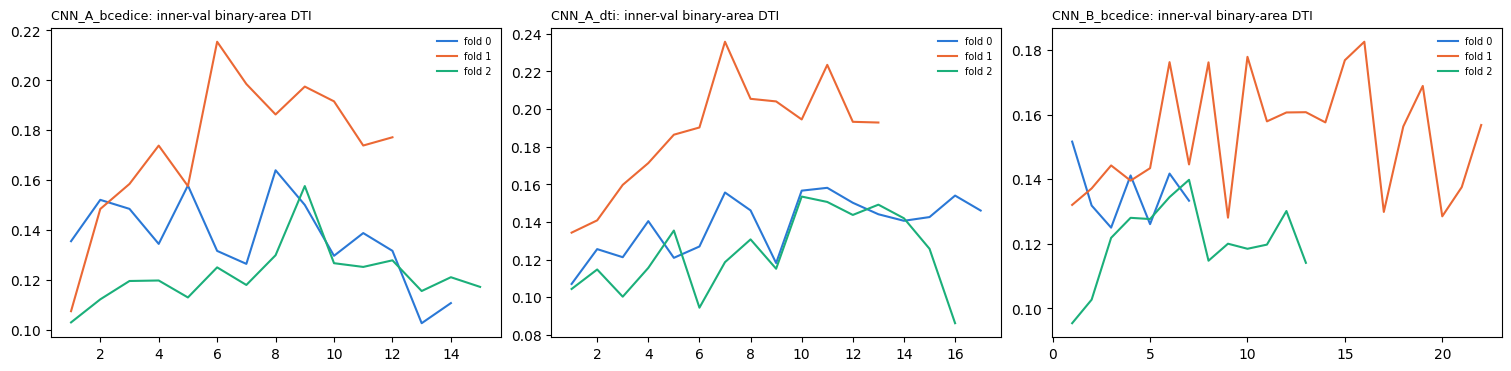

In [10]:
CNN_RUNS = {}
CNN_REQUIRE_CUDA = True   # stop instead of training the U-Net on the CPU (hours instead of minutes)
CNN_GPU = dict(data_on_gpu=True, amp_dtype='auto', channels_last=True, cudnn_benchmark=True, eval_every=1, infer_batch=32)
if RUN_3E:
    try:
        import torch
        print('torch', torch.__version__, '| cuda', torch.cuda.is_available(),
              '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no GPU')
    except ImportError:
        RUN_3E = False
        print('torch not installed -> section 6 skipped (pip install -r requirements-phase3.txt + CUDA torch)')
if RUN_3E and CNN_REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError(f'torch {torch.__version__} has no CUDA. In the GEMS env run\n'
                       '  pip install --force-reinstall torch --index-url https://download.pytorch.org/whl/cu128\n'
                       'restart the kernel and re-run (sections 1-5 are cached). Set CNN_REQUIRE_CUDA=False to train on CPU.')
if RUN_3E:
    free, total = torch.cuda.mem_get_info() if torch.cuda.is_available() else (0, 0)
    print(f'GPU memory free {free / 2**30:.1f} / {total / 2**30:.1f} GiB | bf16: {torch.cuda.is_available() and torch.cuda.is_bf16_supported()}')
    from gems_bench.p3 import cnn3
    RAW = [n for n in G3_NAMES if n.startswith('raw:')]
    ENH = ['terrain:curvature@1km', 'terrain:tilt_edge@5km', 'terrain:ridge@1km', 'terrain:relief@2km',
           'magnetic:thdr@2km', 'magnetic:log_gabor@5km', 'magnetic:coherence@2km', 'gravity:thdr@2km',
           'gravity:log_gabor@2km', 'basement:tilt_edge@10km']
    ctx.store.build(sorted(set(RAW + ENH)), verbose=False)
    CNN_SPECS = {
        'CNN_A_bcedice': cnn3.cnn_a_spec(RAW, name='CNN_A_bcedice', loss='bce_dice', seed=CFG.seed, **CNN_GPU),
        'CNN_A_dti': cnn3.cnn_a_spec(RAW, name='CNN_A_dti', loss='dti', seed=CFG.seed, **CNN_GPU),
        'CNN_B_bcedice': cnn3.cnn_a_spec(RAW + ENH, name='CNN_B_bcedice', loss='bce_dice', seed=CFG.seed, **CNN_GPU),
    }
    for key in CNN_SELECT:
        spec = CNN_SPECS[key]
        exp = f'p3_{key}_p{spec.patch_px}_s{CFG.seed}'
        CNN_RUNS[key] = cnn3.run_cnn3_cv(ctx, exp, spec, input_config=key, overwrite=OVERWRITE)
        ALL_MAPS[key] = ctx.oof(exp)
        manifest_row(exp, '3E', 'cnn_cv', {'loss': spec.loss, 'patch_px': spec.patch_px, 'epochs': spec.epochs,
                                          'lr': spec.lr, 'ignore_px': spec.ignore_px}, len(spec.channels), CNN_RUNS[key].dir)
    keys = list(CNN_RUNS) + [m for m in ('G3',) if m in ALL_MAPS]
    cgc = budget.geo_curves(ctx, keys, maps={k: ALL_MAPS[k] for k in keys})
    ccf = budget.crossfit_area(cgc).set_index('model')
    cpool = budget.pool_models(cgc)
    SEGC = budget.segment_recall_at_budget(ctx, {k: ALL_MAPS[k] for k in keys}, MATCH_FRAC) if ctx.seg is not None else {}
    rows = []
    for k in keys:
        at = cpool[(cpool.model == k) & (cpool.target_frac == MATCH_FRAC)].iloc[0]
        row = {'model': k, 'dti_crossfit_area': ccf.loc[k, 'dti_crossfit_area'], 'fold_min': ccf.loc[k, 'fold_min'],
               'fold_max': ccf.loc[k, 'fold_max'], 'recall300_at_match': at['recall@300m'],
               'far_share_at_match': at['far_area_km2'] / max(at['area_km2'], 1e-9)}
        if k in CNN_RUNS:
            s = CNN_RUNS[k].state['summary']
            mf = CNN_RUNS[k].table('metrics_fold')
            row.update(dti_raw_pooled=s['dti_pooled_raw'], best_epochs=s['best_iters'], train_seconds=s['train_seconds'],
                       peak_rss_mb=s['peak_rss_mb'], gpu_peak_mb=float(pd.to_numeric(mf['gpu_peak_mb'], errors='coerce').max()))
        if k in SEGC:
            for r in geo_eval.stratified_recall(SEGC[k], ['length_bin', 'primary_archetype']).to_dict('records'):
                row['recall300_' + r['stratum'] + '_' + r['value']] = r['recall@300m']
        rows.append(row)
    CNN_TABLE = pd.DataFrame(rows)
    save(CNN_TABLE, 'cnn_benchmark', 'U-Net vs G3: area DTI, folds, recall by length / archetype, runtime, memory', headline=True)
    display(CNN_TABLE.round(4).T)
    fig, axs = plt.subplots(1, len(CNN_RUNS), figsize=(5 * len(CNN_RUNS), 3.6), squeeze=False, constrained_layout=True)
    for ax, (k, run) in zip(axs[0], CNN_RUNS.items()):
        h = run.table('history')
        for fo, g in h.groupby('fold'):
            ax.plot(g.epoch, g.inner_dti_binary_best, lw=1.5, color=['#2a78d6', '#eb6834', '#1baf7a'][int(fo) % 3], label=f'fold {fo}')
        ax.set_title(k + ': inner-val binary-area DTI', fontsize=9, loc='left')
        ax.legend(fontsize=7, frameon=False)
    show(fig, 'cnn_training_curves', 'Inner-validation binary-area DTI per epoch and fold')

In [11]:
if RUN_3E and CNN_RUNS:
    for key in [k for k in CNN_DISC_SELECT if k in CNN_RUNS]:
        spec = CNN_SPECS[key]
        epochs = max(spec.min_epochs, int(np.median(CNN_RUNS[key].state['summary']['best_iters'])))
        stack = cnn3.device_stack(cnn3.prepare_stack(spec, ctx)[0], spec, cnn3.device_of())   # once per config, reused by all splits
        for d in range(ctx.splits.n_splits):
            cnn3.run_cnn3_discovery(ctx, f'disc{d}_{key}', spec, d, epochs, overwrite=OVERWRITE, stack=stack)
            manifest_row(f'disc{d}_{key}', '3E', 'cnn_discovery', {'epochs': epochs, 'split': d}, len(spec.channels),
                         ctx.paths.experiments / f'disc{d}_{key}')
        del stack
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    cd = [k for k in CNN_DISC_SELECT if k in CNN_RUNS] + ['G3', 'G1']
    CDC, CDO = discovery3.discovery_curves(ctx, cd, policies=('excl', 'retained_fp'), variants=('model',))
    CDS = discovery3.discovery_summary(CDC)
    save(CDS, 'cnn_pseudo_discovery', 'CNN vs GBM pseudo-discovery (matched budgets + cross-fitted area)')
    display(CDS[CDS.row == 'crossfit_area'].pivot_table(index='model', columns='policy', values='dti').round(4))
    csys = discovery3.systems_at_budget(ctx, CDO, MATCH_FRAC)
    display(discovery3.sensitivity_exact(csys).pivot_table(index=['stratum', 'value'], columns='model',
                                                           values='weighted_recall').round(3))

[disc0_CNN_A_bcedice] ep   1 loss 1.4359 inner nan  (14s train, 0s eval)
[disc0_CNN_A_bcedice] ep   2 loss 1.2555 inner nan  (14s train, 0s eval)
[disc0_CNN_A_bcedice] ep   3 loss 1.1643 inner nan  (14s train, 0s eval)
[disc0_CNN_A_bcedice] ep   4 loss 1.1049 inner nan  (14s train, 0s eval)
[disc0_CNN_A_bcedice] ep   5 loss 1.0605 inner nan  (14s train, 0s eval)
[disc0_CNN_A_bcedice] ep   6 loss 1.0031 inner nan  (15s train, 0s eval)
[disc0_CNN_A_bcedice] ep   7 loss 0.9516 inner nan  (16s train, 0s eval)
[disc0_CNN_A_bcedice] ep   8 loss 0.9227 inner nan  (16s train, 0s eval)
[disc1_CNN_A_bcedice] ep   1 loss 1.4347 inner nan  (14s train, 0s eval)
[disc1_CNN_A_bcedice] ep   2 loss 1.2564 inner nan  (15s train, 0s eval)
[disc1_CNN_A_bcedice] ep   3 loss 1.1544 inner nan  (16s train, 0s eval)
[disc1_CNN_A_bcedice] ep   4 loss 1.0936 inner nan  (16s train, 0s eval)
[disc1_CNN_A_bcedice] ep   5 loss 1.0244 inner nan  (16s train, 0s eval)
[disc1_CNN_A_bcedice] ep   6 loss 0.9631 inner nan 

policy,excl,retained_fp
model,,
CNN_A_bcedice,0.1450,0.0756
G1,0.1001,0.0849
G3,0.0752,0.0585


model              CNN_A_bcedice     G1     G3
stratum     value                             
length_bin  10-20          0.185  0.179  0.118
            20-50          0.237  0.258  0.181
            5-10           0.101  0.133  0.110
            >50            0.291  0.397  0.204
region_name CC             0.157  0.150  0.161
            CW             0.055  0.137  0.016
            NC             0.358  0.435  0.208
            NE             0.364  0.341  0.244
            NW             0.189  0.195  0.132
            SC             0.196  0.317  0.193
            SE             0.034  0.000  0.000

## 7 · Phase 3F — candidate lineaments (interpretation, not the submission)

The best geographic model's OOF map (each region predicted by a model that never saw it) is smoothed at 300 m and 600 m; Hessian ridge non-maximum suppression splits wide probability blobs into crest lines inside the top 5 % area; skeletons are split at junctions and traced. Each segment gets length, strike, sinuosity, curvature, probability, mean multi-modal evidence (magnetic / gravity THDR, terrain curvature and ridge, shear strain) and distance to mapped faults; the rank score is a documented heuristic. Geophysical edges are evidence, never confirmation; no dominant-strike filter. Thinned masks are scored against plain top-a masks of the same area before any thinning could be used in a submission.

,top_frac,n_components,largest_km2,share_in_largest,share_in_top10,median_km2
0,0.02,1248,120.69,0.117,0.508,0.02
1,0.05,3216,243.03,0.094,0.543,0.02
2,0.10,6455,658.86,0.128,0.466,0.02
3,0.20,8539,1728.40,0.167,0.635,0.02


scale 300 m: 571 segments
scale 600 m: 294 segments


,n,km
status,,
near_mapped_extension,251,951.6
new_candidate,216,600.2
on_mapped_fault,104,442.8


,rank_new,length_km,strike_deg,sinuosity,ps_mean,n_supporting_modalities,dist_mapped_median_km,lon_mid,lat_mid
17,1.0,8.194,8.861,1.462,0.664,4,2.921,-118.400,39.291
22,2.0,6.967,128.131,1.099,0.704,4,3.453,-119.619,39.817
24,3.0,8.218,3.875,1.388,0.723,3,2.405,-118.021,39.614
25,4.0,14.212,111.105,2.485,0.641,2,5.063,-119.506,39.552
27,5.0,5.870,22.218,1.082,0.691,4,2.267,-118.196,39.201
31,6.0,11.864,28.527,1.233,0.626,2,2.126,-119.324,39.921
36,7.0,5.831,4.354,1.060,0.649,4,2.652,-119.560,39.407
45,8.0,5.687,158.851,1.109,0.624,4,3.748,-118.668,38.887
47,9.0,8.408,134.539,1.212,0.674,2,2.062,-118.521,39.262
48,10.0,4.373,176.509,1.090,0.699,4,6.428,-119.395,39.959


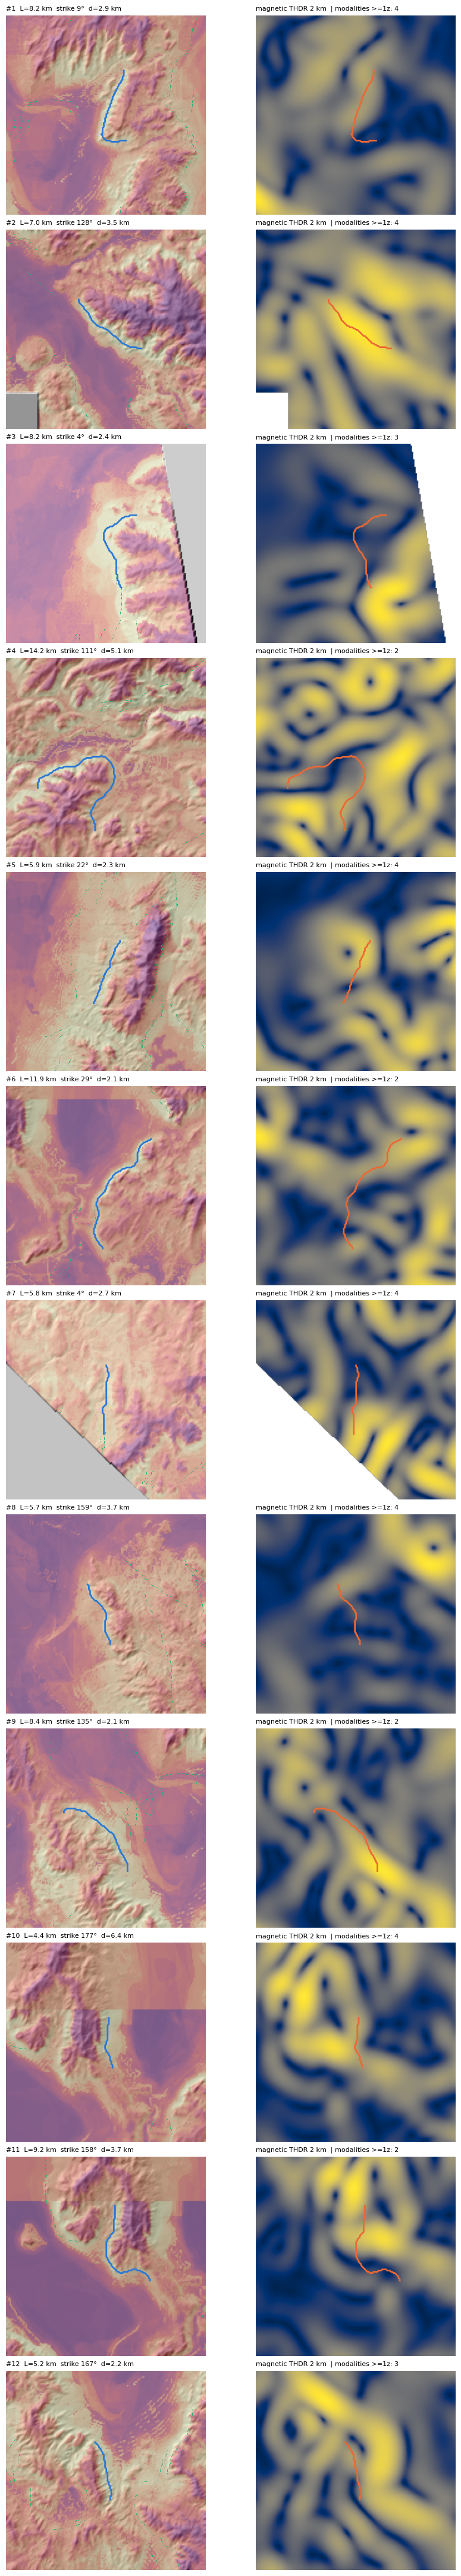

,width_px,area_frac,dti_thinned,dti_topmask_same_area
0,0,0.0039,0.0482,0.0335
1,1,0.0155,0.0722,0.0826
2,2,0.0282,0.0846,0.1021


In [12]:
if RUN_3F:
    LIN_MODEL = 'G3'
    if 'AREA_CF' in globals():
        cand = AREA_CF[AREA_CF.model.isin(['G1', 'G2', 'G3', 'G4'])]
        LIN_MODEL = cand.sort_values('dti_crossfit_area').model.iloc[-1] if len(cand) else 'G3'
    p = ALL_MAPS[LIN_MODEL]
    BLOBS = pd.DataFrame([lineaments.blob_stats(p, ctx.data.valid, fr) for fr in (0.02, 0.05, 0.10, 0.20)])
    save(BLOBS, 'blob_stats_' + LIN_MODEL, 'Connected-component sizes of plain top-a masks (blob diagnosis)')
    display(BLOBS.round(3))
    LIN = {}
    for sc in LIN_SCALES:
        LIN[sc] = lineaments.extract_candidates(ctx, p, scale_m=sc, top_frac=LIN_TOP_FRAC, model=LIN_MODEL)
        print(f'scale {sc:g} m: {len(LIN[sc][0])} segments')
    CAND, CAND_LAB, CAND_PATHS = LIN[LIN_SCALES[0]]
    gp = lineaments.write_lineaments(ctx, CAND, CAND_PATHS, OUT / 'candidate_lineaments.gpkg')
    ctx.manifest.add('candidate_lineaments', Path(gp), 'vector', f'Ranked candidate lineaments from {LIN_MODEL} OOF (interpretation only)')
    for sc in LIN_SCALES[1:]:
        g2 = lineaments.write_lineaments(ctx, LIN[sc][0], LIN[sc][2], ctx.paths.datasets / f'candidate_lineaments_{sc:g}m.gpkg')
        ctx.manifest.add(f'candidate_lineaments_{sc:g}m', Path(g2), 'vector', 'Candidate lineaments at a coarser smoothing scale')
    display(CAND.groupby('status').agg(n=('cand_id', 'size'), km=('length_km', 'sum')).round(1))
    cols = ['rank_new', 'length_km', 'strike_deg', 'sinuosity', 'ps_mean', 'n_supporting_modalities',
            'dist_mapped_median_km', 'lon_mid', 'lat_mid']
    display(CAND[CAND.status == 'new_candidate'][[c for c in cols if c in CAND]].head(15).round(3))
    show(lineaments.atlas_figure(ctx, CAND, CAND_PATHS, p, n=12), 'candidate_atlas',
         'Top-ranked new candidate lineaments (terrain + probability, magnetic edges)', where=OUT)
    TH = lineaments.thinned_mask_dti(ctx, p, CAND_LAB > 0)
    vpx = ctx.data.valid.sum()
    rows = []
    for w, g in TH.groupby('width_px'):
        fr = g.area_px.sum() / vpx
        zc = curves.zone_curves(p, ctx.data.labels, ctx.folds.fold_map, ctx.data.valid, fracs=(fr,))
        rows.append({'width_px': w, 'area_frac': fr, 'dti_thinned': curves.dti_from(g), 'dti_topmask_same_area': curves.dti_from(zc)})
    THIN = pd.DataFrame(rows)
    save(THIN, 'thinned_vs_topmask_dti', 'Does thinning to skeleton lines beat a plain top-a mask of the same area?')
    display(THIN.round(4))

## 8 · Phase 3G — ensemble validation (RQ1, RQ6)

(a) **Decomposition of the Phase-2 0.1125**: the rank ensemble re-scored exactly as in Phase 2 (ordinal ranks, rank grid applied to its values), with average ties, and every member under the same rank grid and under the binary top-a rule. (b) **Nested evaluation**: members alone, the best single member chosen on the training folds, probability mean, rank mean, weighted rank mean (weights + budget chosen jointly on the other folds), logistic stacking and isotonic-calibrated fusion (fitted on the other folds). (c) Pseudo-discovery for the equal-weight rank ensemble of discovery-capable members. (d) Promotion only if the ensemble beats the nested best single model in >= 2 folds, by >= 0.003 pooled, and is not worse on pseudo-discovery.

In [13]:
if RUN_3G:
    if 'SCORERS' not in globals():
        SCORERS = transforms.FoldScorers(ctx.data.labels, ctx.folds.fold_map, ctx.data.valid)
    DECOMP = ensemble3.decompose_rank_ensemble(ctx, SCORERS)
    save(DECOMP, 'rank_ensemble_decomposition', 'Phase-2 rank ensemble vs members under identical transforms')
    display(DECOMP[['model', 'family', 'dti_crossfit', 'fold_min', 'fold_max']].round(4))
    members = {m: ALL_MAPS[m] for m in ('G1', 'G3', 'G4', 'B0_lineament') if m in ALL_MAPS}
    for k in CNN_RUNS:
        members[k] = ALL_MAPS[k]
    ENS_SUM, ENS_PER = ensemble3.nested_ensemble_eval(ctx, members, rng=RNG)
    save(ENS_SUM, 'ensemble_validation', 'Nested ensemble evaluation vs nested best single model', headline=True)
    save(ENS_PER, 'ensemble_validation_per_fold', 'Per-fold choices (weights, budget, fusion fit) and held-out DTI')
    display(ENS_SUM.round(4))
    cands = ['G1', 'G3', 'B0_lineament'] + [k for k in CNN_DISC_SELECT if k in CNN_RUNS]
    disc_members = [m for m in cands if all(ctx.discovery_pred(m, d) is not None for d in range(ctx.splits.n_splits))]
    EXTRA = ensemble3.discovery_ensemble_preds(ctx, disc_members, None, 'ens')
    DCE, _ = discovery3.discovery_curves(ctx, disc_members + ['ens'], policies=('excl', 'retained_fp'), variants=('model',),
                                         extra_preds=EXTRA)
    DSE = discovery3.discovery_summary(DCE)
    save(DSE, 'ensemble_pseudo_discovery', 'Equal-weight rank ensemble of discovery-capable members vs members')
    display(DSE[DSE.row == 'crossfit_area'].pivot_table(index='model', columns='policy', values='dti').round(4))
    methods = [m for m in ENS_SUM.method if not m.startswith('single') and m != 'best_single_nested']
    DECISIONS = pd.DataFrame([ensemble3.promotion_decision(ENS_SUM, DSE, m) for m in methods])
    save(DECISIONS, 'ensemble_promotion', 'Promotion rule outcome per ensemble method')
    display(DECISIONS)

,model,family,dti_crossfit,fold_min,fold_max
0,ens_rank_mean (Phase-2 reported),p2_rank_grid_on_values,0.1125,0.0537,0.1281
1,ens_rank_mean[ordinal],p2_rank_grid_on_values,0.1125,0.0537,0.1281
2,ens_rank_mean[average],p2_rank_grid_on_values,0.1126,0.0536,0.1281
3,G3[ordinal rank],p2_rank_grid_on_values,0.1210,0.1037,0.1436
4,G4[ordinal rank],p2_rank_grid_on_values,0.1148,0.0940,0.1300
5,G2[ordinal rank],p2_rank_grid_on_values,0.0973,0.0000,0.1070
6,ens_rank_mean[average],hard_threshold,0.1160,0.0973,0.1321
7,G3,hard_threshold,0.1154,0.0993,0.1370
8,G4,hard_threshold,0.1127,0.0977,0.1237
9,G2,hard_threshold,0.0974,0.0797,0.1111


,method,dti_pooled,fold_min,fold_max,folds_beating_best_single,mean_delta_vs_best_single,dti_fold0,dti_fold1,dti_fold2
10,weighted_rank(step=0.25),0.1504,0.1292,0.1701,3,0.0255,0.1701,0.1463,0.1292
9,rank_mean,0.1483,0.1325,0.1726,3,0.0243,0.1726,0.1369,0.1325
12,iso_mean,0.1474,0.1234,0.1688,3,0.0225,0.1688,0.1234,0.1444
11,stack_lr,0.1422,0.1304,0.1564,3,0.0175,0.1564,0.1349,0.1304
0,single:G1,0.1327,0.1165,0.1490,2,0.0081,0.1490,0.1165,0.1280
5,single:CNN_A_dti,0.1302,0.1150,0.1376,1,0.0065,0.1376,0.1360,0.1150
8,prob_mean,0.1299,0.1169,0.1430,3,0.0068,0.1430,0.1169,0.1297
7,best_single_nested,0.1244,0.1150,0.1376,0,0.0000,0.1376,0.1165,0.1150
1,single:G3,0.1154,0.0993,0.1370,0,-0.0097,0.1370,0.0993,0.1037
2,single:G4,0.1127,0.0977,0.1237,0,-0.0111,0.1237,0.1145,0.0977


policy,excl,retained_fp
model,,
B0_lineament,0.0393,0.0380
CNN_A_bcedice,0.1450,0.0756
G1,0.1001,0.0849
G3,0.0752,0.0585
ens,0.1017,0.0809


,method,promote,pooled_gain,folds_beating,discovery
0,weighted_rank(step=0.25),False,0.026013,3,discovery ens 0.0809 vs best member 0.0849
1,rank_mean,False,0.023916,3,discovery ens 0.0809 vs best member 0.0849
2,iso_mean,False,0.023012,3,discovery ens 0.0809 vs best member 0.0849
3,stack_lr,False,0.017843,3,discovery ens 0.0809 vs best member 0.0849
4,prob_mean,False,0.005553,3,discovery ens 0.0809 vs best member 0.0849


## 9 · Phase 3H — results, error atlas and decision

All single models, Phase-3 LightGBM configs and CNNs are re-scored under one rule (binary per-fold top-a mask, area cross-fitted). The fold-specific error atlas shows recovered / missed faults and near / far false positives for the best model at its cross-fitted budget. `PHASE3_FINDINGS.md` evaluates the conditional rules on whatever tables exist and writes *pending* elsewhere.

,model,dti_crossfit_area,dti_insample_best,optimism,fold_min,fold_max,frac_all_folds,frac_fold0,frac_fold1,frac_fold2,dti_fold0,dti_fold1,dti_fold2
2,G1,0.1327,0.1352,0.0026,0.1165,0.1490,0.075,0.100,0.075,0.075,0.1490,0.1165,0.1280
10,CNN_A_dti,0.1302,0.1316,0.0015,0.1150,0.1376,0.075,0.100,0.075,0.075,0.1376,0.1360,0.1150
6,ens_mean,0.1201,0.1214,0.0013,0.1033,0.1454,0.075,0.100,0.075,0.100,0.1454,0.1088,0.1033
8,ens_weighted,0.1154,0.1198,0.0044,0.0993,0.1370,0.075,0.100,0.050,0.100,0.1370,0.0993,0.1037
4,G3,0.1154,0.1198,0.0044,0.0993,0.1370,0.075,0.100,0.050,0.100,0.1370,0.0993,0.1037
7,ens_rank_mean,0.1143,0.1176,0.0033,0.0971,0.1321,0.100,0.125,0.075,0.100,0.1321,0.1087,0.0971
5,G4,0.1127,0.1138,0.0010,0.0977,0.1237,0.100,0.125,0.100,0.100,0.1237,0.1145,0.0977
11,CNN_B_bcedice,0.1109,0.1116,0.0006,0.1067,0.1165,0.100,0.125,0.100,0.100,0.1067,0.1165,0.1108
9,CNN_A_bcedice,0.1092,0.1115,0.0023,0.1072,0.1138,0.075,0.100,0.075,0.075,0.1072,0.1138,0.1073
3,G2,0.0974,0.0992,0.0018,0.0797,0.1111,0.125,0.125,0.100,0.125,0.1111,0.1018,0.0797


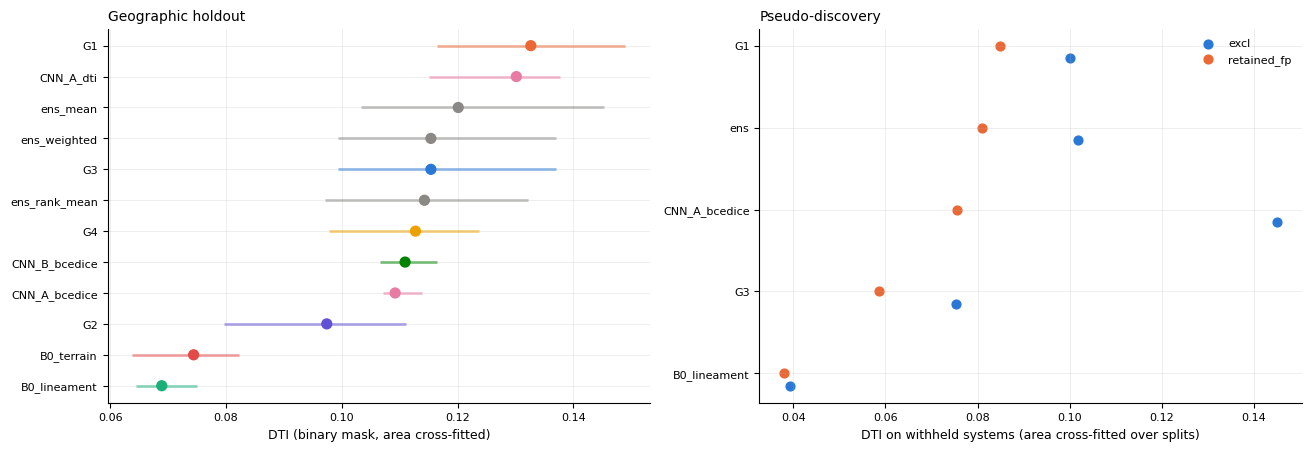

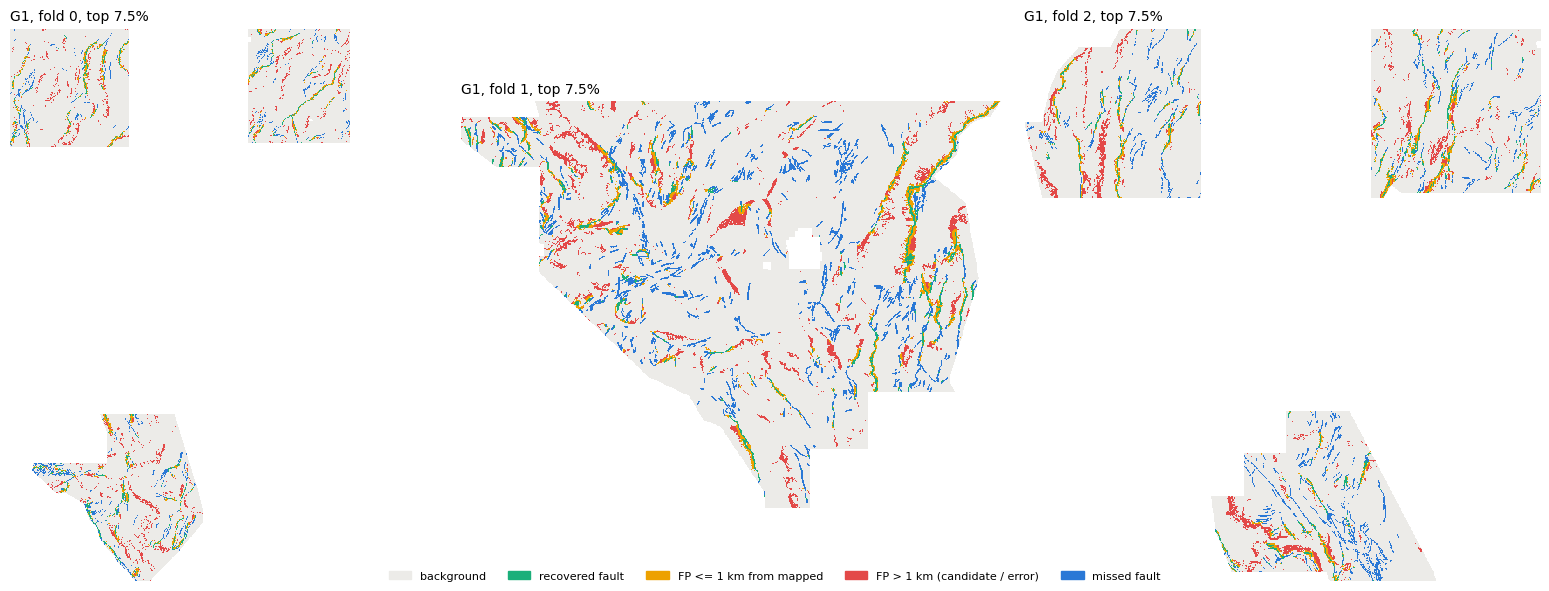

# GEMS — Phase 3 findings

_Generated 2026-10-21 02:32 from saved artifacts in outputs/phase3. Local validation only; no number here is a leaderboard score._

## RQ1 — Are calibration / rank-ensemble gains real?

Audit: 3 FAIL, 16 WARN, 2 FIXED (details: calibration_audit.csv, calibration_findings.md).

| model                            | family                 |   dti_crossfit |   fold_min |   fold_max |   n_params |   dti_insample |   optimism |   choice_on_grid_edge | param_all_folds                                               |   dti_fold0 | param_fold0                                |   dti_fold1 | param_fold1                                |   dti_fold2 | param_fold2                                |
|:---------------------------------|:-----------------------|---------------:|-----------:|-----------:|-----------:|---------------:|-----------:|----------------------:|:--------------------------------------------------------------|------------:|:-------------------------------------------|------------:|:-------------------------------------------|------------:|:-------------------------------------------|
| ens_rank_mean (Phase-2 reported) | p2_rank_grid_on_values |         0.1125 |     0.0537 |     0.1281 |        nan |       nan      |   nan      |                   nan | nan                                                           |    nan      | nan                                        |    nan      | nan                                        |    nan      | nan                                        |
| ens_rank_mean[ordinal]           | p2_rank_grid_on_values |         0.1125 |     0.0537 |     0.1281 |         45 |         0.1146 |     0.002  |                     1 | {"param": "{\"gamma\": 1.0, \"scale\": 2.0, \"floor\": 0.8}"} |      0.1281 | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0.1139 | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0.0537 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |
| ens_rank_mean[average]           | p2_rank_grid_on_values |         0.1126 |     0.0536 |     0.1281 |         45 |         0.1145 |     0.002  |                     1 | {"param": "{\"gamma\": 1.0, \"scale\": 2.0, \"floor\": 0.8}"} |      0.1281 | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0.1139 | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0.0536 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |
| G3[ordinal rank]                 | p2_rank_grid_on_values |         0.121  |     0.1037 |     0.1436 |         45 |         0.121  |     0      |                     1 | {"param": "{\"gamma\": 1.0, \"scale\": 2.0, \"floor\": 0.9}"} |      0.1436 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |      0.1167 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |      0.1037 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |
| G4[ordinal rank]                 | p2_rank_grid_on_values |         0.1148 |     0.094  |     0.13   |         45 |         0.1148 |     0      |                     1 | {"param": "{\"gamma\": 1.0, \"scale\": 2.0, \"floor\": 0.9}"} |      0.13   | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |      0.1165 | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |      0.094  | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |
| G2[ordinal rank]                 | p2_rank_grid_on_values |         0.0973 |     0      |     0.107  |         45 |         0.1002 |     0.003  |                     1 | {"param": "{\"gamma\": 1.0, \"scale\": 2.0, \"floor\": 0.8}"} |      0.1027 | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0.107  | {"gamma": 1.0, "scale": 2.0, "floor": 0.8} |      0      | {"gamma": 1.0, "scale": 2.0, "floor": 0.9} |
| ens_rank_mean[average]           | hard_threshold         |         0.116  |     0.0973 |     0.1321 |         14 |         0.1177 |     0.0017 |                     0 | {"param": "{\"a\": 0.1}"}                                     |      0.1321 | {"a": 0.125}                               |      0.1152 | {"a": 0.1}                                 |      0.0973 | {"a": 0.1}                                 |
| G3                               | hard_threshold         |         0.1154 |     0.0993 |     0.137  |         14 |         0.1198 |     0.0044 |                     0 | {"param": "{\"a\": 0.075}"}                                   |      0.137  | {"a": 0.1}                                 |      0.0993 | {"a": 0.05}                                |      0.1037 | {"a": 0.1}                                 |
| G4                               | hard_threshold         |         0.1127 |     0.0977 |     0.1237 |         14 |         0.1138 |     0.001  |                     0 | {"param": "{\"a\": 0.1}"}                                     |      0.1237 | {"a": 0.125}                               |      0.1145 | {"a": 0.1}                                 |      0.0977 | {"a": 0.1}                                 |
| G2                               | hard_threshold         |         0.0974 |     0.0797 |     0.1111 |         14 |         0.0992 |     0.0018 |                     0 | {"param": "{\"a\": 0.125}"}                                   |      0.1111 | {"a": 0.125}                               |      0.1018 | {"a": 0.1}                                 |      0.0797 | {"a": 0.125}                               |

Rule: if G3 under the Phase-2 rank transform is within 0.01 of 0.1125 the gain is a transform artifact. Verdict: **transform artifact** — G3 alone under the same rank transform is within 0.01 of the ensemble (gap -0.0085); binary-mask DTI ensemble 0.1160 vs G3 0.1154

## RQ3 — Recovery at matched prediction-area budgets

| model         |   dti_crossfit_area |   dti_insample_best |   optimism |   fold_min |   fold_max |   frac_all_folds |   frac_fold0 |   frac_fold1 |   frac_fold2 |   dti_fold0 |   dti_fold1 |   dti_fold2 |
|:--------------|--------------------:|--------------------:|-----------:|-----------:|-----------:|-----------------:|-------------:|-------------:|-------------:|------------:|------------:|------------:|
| G1            |              0.1327 |              0.1352 |     0.0026 |     0.1165 |     0.149  |            0.075 |        0.1   |        0.075 |        0.075 |      0.149  |      0.1165 |      0.128  |
| G2            |              0.0974 |              0.0992 |     0.0018 |     0.0797 |     0.1111 |            0.125 |        0.125 |        0.1   |        0.125 |      0.1111 |      0.1018 |      0.0797 |
| G3            |              0.1154 |              0.1198 |     0.0044 |     0.0993 |     0.137  |            0.075 |        0.1   |        0.05  |        0.1   |      0.137  |      0.0993 |      0.1037 |
| G4            |              0.1127 |              0.1138 |     0.001  |     0.0977 |     0.1237 |            0.1   |        0.125 |        0.1   |        0.1   |      0.1237 |      0.1145 |      0.0977 |
| B0_lineament  |              0.0689 |              0.0697 |     0.0008 |     0.0646 |     0.075  |            0.25  |        0.25  |        0.2   |        0.25  |      0.0646 |      0.075  |      0.0689 |
| B0_terrain    |              0.0744 |              0.0747 |     0.0002 |     0.0638 |     0.0822 |            0.4   |        0.3   |        0.3   |        0.4   |      0.0638 |      0.0822 |      0.0777 |
| ens_mean      |              0.1201 |              0.1214 |     0.0013 |     0.1033 |     0.1454 |            0.075 |        0.1   |        0.075 |        0.1   |      0.1454 |      0.1088 |      0.1033 |
| ens_rank_mean |              0.1143 |              0.1176 |     0.0033 |     0.0971 |     0.1321 |            0.1   |        0.125 |        0.075 |        0.1   |      0.1321 |      0.1087 |      0.0971 |
| ens_weighted  |              0.1154 |              0.1198 |     0.0044 |     0.0993 |     0.137  |            0.075 |        0.1   |        0.05  |        0.1   |      0.137  |      0.0993 |      0.1037 |

Matched budgets (pooled over geographic folds):

| model         |   target_frac |   area_km2 |    dti |   recall_w |   recall@100m |   recall@200m |   recall@300m |      tp_w |     fp_w |   far_area_km2 |
|:--------------|--------------:|-----------:|-------:|-----------:|--------------:|--------------:|--------------:|----------:|---------:|---------------:|
| G1            |          0.01 |     524.8  | 0.0762 |     0.0727 |        0.0712 |        0.0859 |        0.1002 |  4426.65  |  42556.7 |         199.08 |
| G3            |          0.01 |     516.7  | 0.0655 |     0.0624 |        0.0609 |        0.0719 |        0.0855 |  3797.51  |  42718   |         163.58 |
| ens_weighted  |          0.01 |     516.7  | 0.0655 |     0.0624 |        0.0609 |        0.0719 |        0.0855 |  3797.51  |  42718   |         163.58 |
| ens_mean      |          0.01 |     517.03 | 0.0566 |     0.0541 |        0.0529 |        0.0631 |        0.0752 |  3293.48  |  44082.6 |         213.49 |
| G4            |          0.01 |     518.55 | 0.0486 |     0.0466 |        0.0453 |        0.0544 |        0.0636 |  2835.19  |  45106.8 |         235.51 |
| ens_rank_mean |          0.01 |     516.6  | 0.047  |     0.0451 |        0.0439 |        0.0539 |        0.0652 |  2743.86  |  45623.5 |         251.03 |
| B0_lineament  |          0.01 |     516.6  | 0.0292 |     0.028  |        0.0275 |        0.0298 |        0.032  |  1706.02  |  46584.6 |         250.37 |
| G2            |          0.01 |     589.35 | 0.029  |     0.0286 |        0.0282 |        0.0338 |        0.04   |  1743.67  |  55155.4 |         404.2  |
| B0_terrain    |          0.01 |     516.6  | 0.0061 |     0.0059 |        0.0057 |        0.0075 |        0.0104 |   362.247 |  50950.6 |         444.71 |
| G1            |          0.02 |    1710.74 | 0.122  |     0.1613 |        0.1599 |        0.1904 |        0.2184 |  9822.07  | 149011   |         855.79 |
| G3            |          0.02 |    1042.97 | 0.0941 |     0.1047 |        0.1032 |        0.1213 |        0.1403 |  6376.23  |  89026.9 |         416.79 |
| ens_weighted  |          0.02 |    1042.97 | 0.0941 |     0.1047 |        0.1032 |        0.1213 |        0.1403 |  6376.23  |  89026.9 |         416.79 |
| ens_mean      |          0.02 |    1033.38 | 0.0814 |     0.0906 |        0.0892 |        0.1049 |        0.1219 |  5519.78  |  90139.6 |         478.26 |
| ens_rank_mean |          0.02 |    1033.19 | 0.0747 |     0.0836 |        0.0811 |        0.0991 |        0.1187 |  5088.69  |  91971.3 |         531.02 |
| G4            |          0.02 |    1080.39 | 0.0741 |     0.0838 |        0.0822 |        0.097  |        0.113  |  5105.35  |  95606.6 |         534.7  |
| G2            |          0.02 |    1254.51 | 0.0588 |     0.0703 |        0.0692 |        0.0844 |        0.0999 |  4283.57  | 116187   |         780.93 |
| B0_lineament  |          0.02 |    1033.18 | 0.0412 |     0.0462 |        0.0457 |        0.0484 |        0.0515 |  2813.01  |  94847.5 |         571.52 |
| B0_terrain    |          0.02 |    1033.18 | 0.0156 |     0.0177 |        0.016  |        0.0217 |        0.0305 |  1078.42  | 101036   |         857.43 |
| G1            |          0.05 |    2691.35 | 0.1335 |     0.217  |        0.215  |        0.253  |        0.2891 | 13212.2   | 237984   |        1380.54 |
| G3            |          0.05 |    2583.2  | 0.1164 |     0.1854 |        0.1827 |        0.2123 |        0.242  | 11291.9   | 230306   |        1319.1  |
| ens_weighted  |          0.05 |    2583.2  | 0.1164 |     0.1854 |        0.1827 |        0.2123 |        0.242  | 11291.9   | 230306   |        1319.1  |
| ens_mean      |          0.05 |    2583.56 | 0.112  |     0.1786 |        0.1768 |        0.2047 |        0.2309 | 10877.7   | 231354   |        1343.3  |
| ens_rank_mean |          0.05 |    2582.94 | 0.1071 |     0.1713 |        0.17   |        0.1969 |        0.2229 | 10432.4   | 233010   |        1411.41 |
| G4            |          0.05 |    2584.12 | 0.1045 |     0.1669 |        0.1642 |        0.1892 |        0.2148 | 10164.7   | 232453   |        1407.52 |
| G2            |          0.05 |    2811.25 | 0.0877 |     0.1478 |        0.1467 |        0.1751 |        0.2035 |  9000.69  | 260693   |        1728.65 |
| B0_lineament  |          0.05 |    2582.94 | 0.0584 |     0.0939 |        0.0928 |        0.0988 |        0.1061 |  5718.46  | 240633   |        1590.87 |
| B0_terrain    |          0.05 |    2582.94 | 0.0369 |     0.0603 |        0.0557 |        0.0746 |        0.0975 |  3673.46  | 250092   |        2031.61 |
| G1            |          0.1  |    5201.24 | 0.1339 |     0.3225 |        0.3202 |        0.3675 |        0.4126 | 19639.2   | 470385   |        2936.26 |
| ens_mean      |          0.1  |    5166.19 | 0.1214 |     0.2915 |        0.2924 |        0.3239 |        0.3532 | 17750.8   | 469868   |        2938.46 |
| G3            |          0.1  |    5166.61 | 0.1196 |     0.2873 |        0.2852 |        0.3218 |        0.3556 | 17496.7   | 470688   |        2971.2  |
| ens_weighted  |          0.1  |    5166.61 | 0.1196 |     0.2873 |        0.2852 |        0.3218 |        0.3556 | 17496.7   | 470688   |        2971.2  |
| ens_rank_mean |          0.1  |    5165.87 | 0.1176 |     0.283  |        0.2828 |        0.3174 |        0.3474 | 17235.8   | 471815   |        3004.95 |
| G4            |          0.1  |    5166.3  | 0.1138 |     0.2738 |        0.2703 |        0.3062 |        0.3415 | 16671.6   | 472497   |        3052.87 |
| G2            |          0.1  |    5385.4  | 0.0982 |     0.2451 |        0.2448 |        0.2821 |        0.3151 | 14924.3   | 501662   |        3417.67 |
| B0_lineament  |          0.1  |    5165.87 | 0.066  |     0.1603 |        0.159  |        0.1681 |        0.1786 |  9761.38  | 485715   |        3357.69 |
| B0_terrain    |          0.1  |    5165.87 | 0.0573 |     0.1408 |        0.1314 |        0.1703 |        0.2136 |  8574.94  | 496370   |        3871.03 |
| G1            |          0.2  |   10332.9  | 0.1192 |     0.4808 |        0.4769 |        0.5372 |        0.5955 | 29280     | 954961   |        6449.36 |
| G3            |          0.2  |   10332.5  | 0.109  |     0.4395 |        0.4392 |        0.479  |        0.515  | 26764.1   | 957686   |        6443.63 |
| ens_weighted  |          0.2  |   10332.5  | 0.109  |     0.4395 |        0.4392 |        0.479  |        0.515  | 26764.1   | 957686   |        6443.63 |
| ens_mean      |          0.2  |   10331.7  | 0.1088 |     0.4387 |        0.4388 |        0.4779 |        0.5132 | 26715.7   | 957715   |        6418.96 |

G3 beats G1 in every fold at area fractions: none.

Withheld systems recovered by G1 but missed by G3 at the same budget: 8

Truth-density sensitivity (optimal area if hidden truth is sparser):

| model        |   rho |   best_frac |   best_dti |
|:-------------|------:|------------:|-----------:|
| B0_lineament |  1    |      0.25   |     0.0697 |
| B0_lineament |  0.5  |      0.125  |     0.039  |
| B0_lineament |  0.25 |      0.05   |     0.0226 |
| B0_lineament |  0.1  |      0.01   |     0.0113 |
| B0_lineament |  0.05 |      0.005  |     0.0069 |
| B0_terrain   |  1    |      0.4    |     0.0747 |
| B0_terrain   |  0.5  |      0.25   |     0.0397 |
| B0_terrain   |  0.25 |      0.25   |     0.0206 |
| B0_terrain   |  0.1  |      0.2    |     0.0085 |
| B0_terrain   |  0.05 |      0.2    |     0.0043 |
| G1           |  1    |      0.075  |     0.1352 |
| G1           |  0.5  |      0.05   |     0.0865 |
| G1           |  0.25 |      0.02   |     0.0536 |
| G1           |  0.1  |      0.01   |     0.029  |
| G1           |  0.05 |      0.0025 |     0.0181 |
| G2           |  1    |      0.125  |     0.0992 |
| G2           |  0.5  |      0.075  |     0.058  |
| G2           |  0.25 |      0.05   |     0.0332 |
| G2           |  0.1  |      0.05   |     0.0148 |
| G2           |  0.05 |      0.02   |     0.0078 |

## RQ2 — Why LightGBM stops early

| model   |   fold |   iterations_recorded |   best_iter_logloss |   best_iter_auc |   inner_auc_iter1 |   inner_auc_best |   inner_auc_gain_over_iter1 |   train_auc_at_best_ll |   train_auc_last |   generalisation_gap_at_best |   inner_ll_iter1 |   inner_ll_min |   inner_ll_last |   refit_rounds |   n_pos |   n_neg |   ring_share_of_neg |   pu_downweighted |
|:--------|-------:|----------------------:|--------------------:|----------------:|------------------:|-----------------:|----------------------------:|-----------------------:|-----------------:|-----------------------------:|-----------------:|---------------:|----------------:|---------------:|--------:|--------:|--------------------:|------------------:|
| G1      |      0 |                   107 |                  10 |               7 |            0.6485 |           0.6624 |                      0.0139 |                 0.7663 |           0.8666 |                       0.1055 |           0.6876 |         0.6656 |          0.8408 |              7 |   29980 |  450000 |              0.3333 |              6648 |
| G1      |      1 |                   103 |                  51 |               3 |            0.6934 |           0.7191 |                      0.0257 |                 0.8408 |           0.8827 |                       0.1254 |           0.6857 |         0.623  |          0.6356 |              3 |   29626 |  450000 |              0.3333 |              5264 |
| G1      |      2 |                   111 |                  11 |              32 |            0.6142 |           0.656  |                      0.0417 |                 0.7925 |           0.8911 |                       0.1497 |           0.6885 |         0.6673 |          0.9296 |             11 |   25611 |  450000 |              0.3333 |              5433 |
| G2      |      0 |                   124 |                  24 |              27 |            0.5556 |           0.6779 |                      0.1224 |                 0.8636 |           0.9374 |                       0.1894 |           0.6925 |         0.6667 |          0.7962 |             24 |   29980 |  450000 |              0.3333 |              6648 |
| G2      |      1 |                   107 |                   7 |              86 |            0.5259 |           0.6311 |                      0.1052 |                 0.8646 |           0.9435 |                       0.2441 |           0.6925 |         0.6806 |          0.851  |              7 |   29626 |  450000 |              0.3333 |              5264 |
| G2      |      2 |                   102 |                   2 |             100 |            0.545  |           0.6422 |                      0.0972 |                 0.8404 |           0.9471 |                       0.2433 |           0.6913 |         0.6867 |          0.9202 |              2 |   25611 |  450000 |              0.3333 |              5433 |
| G3      |      0 |                   117 |                  17 |              17 |            0.6749 |           0.6841 |                      0.0092 |                 0.8735 |           0.9536 |                       0.1894 |           0.6859 |         0.657  |          0.8732 |             17 |   29980 |  450000 |              0.3333 |              6648 |
| G3      |      1 |                   125 |                  25 |              74 |            0.6085 |           0.7102 |                      0.1017 |                 0.9068 |           0.9628 |                       0.2056 |           0.6882 |         0.6507 |          0.7992 |             25 |   29626 |  450000 |              0.3333 |              5264 |
| G3      |      2 |                   109 |                   9 |              81 |            0.5866 |           0.6402 |                      0.0536 |                 0.8838 |           0.9633 |                       0.2573 |           0.6892 |         0.6755 |          0.9877 |              9 |   25611 |  450000 |              0.3333 |              5433 |
| G4      |      0 |                   110 |                  10 |             110 |            0.5813 |           0.6503 |                      0.069  |                 0.8693 |           0.9551 |                       0.2545 |           0.6894 |         0.6741 |          0.8795 |             10 |   29980 |  450000 |              0.3333 |              6648 |
| G4      |      1 |                   113 |                  13 |              84 |            0.6035 |           0.7063 |                      0.1028 |                 0.9015 |           0.9634 |                       0.2153 |           0.6876 |         0.656  |          0.7879 |             13 |   29626 |  450000 |              0.3333 |              5264 |
| G4      |      2 |                   112 |                  12 |              59 |            0.5974 |           0.6938 |                      0.0965 |                 0.9033 |           0.9671 |                       0.237  |           0.6873 |         0.6655 |          0.9629 |             12 |   25611 |  450000 |              0.3333 |              5433 |

Median inner-val AUC gain after the first tree: 0.083. Rule: < 0.02 means no transferable signal is added by further trees (domain shift / spatial overfit); early stopping is then correct and gains must come from inputs or representation, not boosting rounds.

| config             |   lr | complexity   | sampling   | es   | best_iters            |   dti_crossfit_area |   fold_min |   fold_max |   dti_raw_pooled |   roc_auc_pooled |   recall300_at_match |   far_share_at_match |   pred_q99_minus_q50 |   train_seconds |   inner_auc_iter1 |   inner_auc_best |   best_iter_auc |   best_iter_binary_logloss |   disc_dti_excl |   disc_dti_retained_fp |   rounds |
|:-------------------|-----:|:-------------|:-----------|:-----|:----------------------|--------------------:|-----------:|-----------:|-----------------:|-----------------:|---------------------:|---------------------:|---------------------:|----------------:|------------------:|-----------------:|----------------:|---------------------------:|----------------:|-----------------------:|---------:|
| D0_p2_replica      | 0.05 | C1           | S1         | any  | [17.0, 17.0, 9.0]     |              0.1188 |     0.1039 |     0.1326 |           0.0609 |           0.6731 |               0.2362 |               0.5153 |               0.2046 |           38.52 |            0.6248 |           0.6715 |         67.6667 |                    14.3333 |          0.0772 |                 0.0603 |      nan |
| D1_es_auc          | 0.05 | C1           | S1         | auc  | [17.0, 80.0, 129.0]   |              0.1239 |     0.1142 |     0.1326 |           0.0662 |           0.6313 |               0.2485 |               0.528  |               0.435  |           81.22 |            0.6248 |           0.6719 |         75.3333 |                    14.3333 |        nan      |               nan      |      nan |
| D2_conservative    | 0.05 | C2           | S1         | auc  | [16.0, 93.0, 78.0]    |              0.1307 |     0.1175 |     0.1548 |           0.064  |           0.6548 |               0.2652 |               0.4814 |               0.3141 |           56.72 |            0.5625 |           0.6687 |         62.3333 |                    26.6667 |          0.0791 |                 0.0638 |      nan |
| D3_conservative_lr | 0.01 | C2           | S1         | auc  | [36.0, 376.0, 255.0]  |              0.1303 |     0.1165 |     0.1532 |           0.0619 |           0.6435 |               0.2504 |               0.4835 |               0.2661 |          203.87 |            0.5625 |           0.6678 |        222.333  |                   134      |          0.0743 |                 0.0635 |      nan |
| D4_complex_lr      | 0.01 | C1           | S1         | auc  | [15.0, 428.0, 693.0]  |              0.1171 |     0.1122 |     0.1205 |           0.0625 |           0.6046 |               0.2345 |               0.5338 |               0.3794 |          351.08 |            0.6248 |           0.6753 |        378.667  |                    65.3333 |        nan      |               nan      |      nan |
| D5_conservative_S2 | 0.05 | C2           | S2         | auc  | [33.0, 43.0, 39.0]    |              0.1152 |     0.1018 |     0.1326 |           0.0632 |           0.6592 |               0.2072 |               0.519  |               0.2813 |           15.45 |            0.5866 |           0.6825 |         38.3333 |                    27.3333 |          0.0613 |                 0.0514 |      nan |
| D6_cons_lr_S2      | 0.01 | C2           | S2         | auc  | [125.0, 222.0, 289.0] |              0.1151 |     0.0954 |     0.1346 |           0.0632 |           0.657  |               0.2128 |               0.512  |               0.2861 |           65.8  |            0.5866 |           0.6892 |        212      |                   146.667  |        nan      |               nan      |      nan |
| F1_fixed100_C2     | 0.05 | C2           | S1         | nan  | [100.0, 100.0, 100.0] |              0.1331 |     0.1168 |     0.1577 |           0.0684 |           0.6823 |               0.2618 |               0.4807 |               0.4039 |           38.49 |            0.5625 |           0.6687 |         62.3333 |                    26.6667 |        nan      |               nan      |      100 |
| F2_fixed400_C2     | 0.05 | C2           | S1         | nan  | [400.0, 400.0, 400.0] |              0.1315 |     0.1153 |     0.1496 |           0.074  |           0.6744 |               0.2638 |               0.5039 |               0.5515 |          149.35 |            0.5625 |           0.6687 |         62.3333 |                    26.6667 |          0.0797 |                 0.0561 |      400 |
| F3_fixed400_C1     | 0.05 | C1           | S1         | nan  | [400.0, 400.0, 400.0] |              0.1161 |     0.1101 |     0.1205 |           0.0763 |           0.6661 |               0.2483 |               0.5765 |               0.6118 |          183    |            0.6248 |           0.6719 |         75.3333 |                    14.3333 |        nan      |               nan      |      400 |

Rule: adopt a variant only if its cross-fitted area DTI beats D0 by >= 0.005 without lowering the worst fold.

## RQ5 — Modality contributions (G3 ablation)

| ablation                | dropped                  |   n_features |   spatial_dti |   spatial_fold_min |   disc_dti_excl |   disc_dti_retained_fp |   recall300_at_match |   far_share_at_match |   mean_p_far_from_labels |   jaccard_top_vs_A0 |   recall300_length_bin_<1 |   recall300_length_bin_1-2 |   recall300_length_bin_2-5 |   recall300_length_bin_5-10 |   recall300_length_bin_>10 |   recall300_region_name_CC |   recall300_region_name_CW |   recall300_region_name_NC |   recall300_region_name_NE |   recall300_region_name_NW |   recall300_region_name_SC |   recall300_region_name_SE |   delta_spatial_dti |   delta_disc_dti_excl |   delta_disc_dti_retained_fp |   delta_recall300_at_match |
|:------------------------|:-------------------------|-------------:|--------------:|-------------------:|----------------:|-----------------------:|---------------------:|---------------------:|-------------------------:|--------------------:|--------------------------:|---------------------------:|---------------------------:|----------------------------:|---------------------------:|---------------------------:|---------------------------:|---------------------------:|---------------------------:|---------------------------:|---------------------------:|---------------------------:|--------------------:|----------------------:|-----------------------------:|---------------------------:|
| A0_full                 | ()                       |           52 |        0.1188 |             0.1039 |          0.0772 |                 0.0603 |               0.2362 |               0.5153 |                   0.4258 |              1      |                    0.2052 |                     0.1621 |                     0.2023 |                      0.2916 |                     0.4653 |                     0.2851 |                     0.095  |                     0.2792 |                     0.266  |                     0.1618 |                     0.3033 |                     0.2632 |              0      |                0      |                       0      |                     0      |
| A1_no_terrain           | ('terrain',)             |           33 |        0.0629 |             0.0578 |          0.0241 |                 0.0204 |               0.2219 |               0.6595 |                   0.4892 |              0.1004 |                    0.1866 |                     0.2407 |                     0.2194 |                      0.248  |                     0.2008 |                     0.299  |                     0.3043 |                     0.1836 |                     0.1677 |                     0.316  |                     0.0619 |                     0.2143 |             -0.0559 |               -0.0532 |                      -0.0399 |                    -0.0143 |
| A2_no_magnetic          | ('magnetic',)            |           38 |        0.1143 |             0.1018 |          0.0712 |                 0.0557 |               0.2348 |               0.5304 |                   0.4389 |              0.4518 |                    0.1963 |                     0.1648 |                     0.2027 |                      0.2817 |                     0.469  |                     0.264  |                     0.0921 |                     0.2492 |                     0.2486 |                     0.1738 |                     0.3465 |                     0.2782 |             -0.0045 |               -0.006  |                      -0.0046 |                    -0.0013 |
| A3_no_gravity_basement  | ('gravity', 'basement')  |           40 |        0.1165 |             0.0953 |          0.0699 |                 0.0591 |               0.2045 |               0.5675 |                   0.4634 |              0.3275 |                    0.1501 |                     0.1431 |                     0.1718 |                      0.2518 |                     0.453  |                     0.2182 |                     0.0741 |                     0.3145 |                     0.231  |                     0.1754 |                     0.1964 |                     0.297  |             -0.0022 |               -0.0073 |                      -0.0012 |                    -0.0316 |
| A4_no_seismicity_strain | ('seismicity', 'strain') |           47 |        0.1238 |             0.1125 |          0.1004 |                 0.0832 |               0.2471 |               0.5341 |                   0.4445 |              0.3025 |                    0.1842 |                     0.1771 |                     0.2091 |                      0.3155 |                     0.5    |                     0.1889 |                     0.1757 |                     0.3089 |                     0.2854 |                     0.2605 |                     0.2893 |                     0.3459 |              0.005  |                0.0232 |                       0.0229 |                     0.011  |
| A5_top_features         | top                      |           21 |        0.1131 |             0.0935 |          0.0678 |                 0.0528 |               0.2193 |               0.5609 |                   0.4358 |              0.374  |                    0.1872 |                     0.1647 |                     0.1917 |                      0.267  |                     0.4028 |                     0.2368 |                     0.0659 |                     0.244  |                     0.2456 |                     0.1919 |                     0.2914 |                     0.297  |             -0.0057 |               -0.0095 |                      -0.0075 |                    -0.0168 |

Rules: a modality is *genuine* if removing it lowers both spatial and pseudo-discovery DTI by >= 0.003; *regional shortcut* if removal lowers spatial DTI but not discovery recall, or raises far-from-label confidence share; *noise* if removal improves both. SHAP magnitude alone is never sufficient.

## RQ4 — CNN benchmark

| model         |   dti_crossfit_area |   fold_min |   fold_max |   recall300_at_match |   far_share_at_match |   dti_raw_pooled | best_epochs       |   train_seconds |   peak_rss_mb |   gpu_peak_mb |   recall300_length_bin_<1 |   recall300_length_bin_1-2 |   recall300_length_bin_2-5 |   recall300_length_bin_5-10 |   recall300_length_bin_>10 |   recall300_primary_archetype_gravity_related |   recall300_primary_archetype_moderate_mixed |   recall300_primary_archetype_multi_modal |   recall300_primary_archetype_strong_magnetic |   recall300_primary_archetype_terrain_visible |   recall300_primary_archetype_unassigned |
|:--------------|--------------------:|-----------:|-----------:|---------------------:|---------------------:|-----------------:|:------------------|----------------:|--------------:|--------------:|--------------------------:|---------------------------:|---------------------------:|----------------------------:|---------------------------:|----------------------------------------------:|---------------------------------------------:|------------------------------------------:|----------------------------------------------:|----------------------------------------------:|-----------------------------------------:|
| CNN_A_bcedice |              0.1092 |     0.1072 |     0.1138 |               0.248  |               0.5998 |           0.0711 | [8.0, 6.0, 9.0]   |          705.64 |        1188.7 |       2673.96 |                    0.1926 |                     0.1852 |                     0.2173 |                      0.3092 |                     0.4883 |                                        0.2965 |                                       0.2905 |                                    0.3611 |                                        0.269  |                                        0.442  |                                   0.2027 |
| CNN_A_dti     |              0.1302 |     0.115  |     0.1376 |               0.3509 |               0.6415 |           0.0738 | [11.0, 7.0, 10.0] |          843.57 |        1807.1 |       2343.4  |                    0.294  |                     0.2886 |                     0.3076 |                      0.427  |                     0.5633 |                                        0.3925 |                                       0.3746 |                                    0.4671 |                                        0.3103 |                                        0.4926 |                                   0.3017 |
| CNN_B_bcedice |              0.1109 |     0.1067 |     0.1165 |               0.2465 |               0.605  |           0.0503 | [1.0, 16.0, 7.0]  |          708.94 |        2310.4 |       2542.82 |                    0.2189 |                     0.1885 |                     0.2154 |                      0.2834 |                     0.4658 |                                        0.2812 |                                       0.2294 |                                    0.3442 |                                        0.5    |                                        0.3033 |                                   0.2131 |
| G3            |              0.1154 |     0.0993 |     0.137  |               0.242  |               0.5106 |         nan      | nan               |          nan    |         nan   |        nan    |                    0.1935 |                     0.1641 |                     0.1999 |                      0.3044 |                     0.5165 |                                        0.3506 |                                       0.2637 |                                    0.3812 |                                        0.0172 |                                        0.1883 |                                   0.1906 |

Rule: CNN replaces GBM as primary if cross-fitted area DTI >= GBM + 0.01 and short-fault (<2 km) recall is not lower; a CNN within 0.01 is an ensemble candidate.

## RQ6 — Withheld-system recovery without flooding

| model        | policy      | variant        |   target_frac |      tp_w |             fp_w |    fn_w |   n_truth |     eval_px |          area_px |   area_km2 |   near_mass |   far_area_km2 |   recall@100m |   recall@200m |   recall@300m |    dti |   recall_w |   area_frac | row            |   dti_insample_best |   fold_min |   fold_max |
|:-------------|:------------|:---------------|--------------:|----------:|-----------------:|--------:|----------:|------------:|-----------------:|-----------:|------------:|---------------:|--------------:|--------------:|--------------:|-------:|-----------:|------------:|:---------------|--------------------:|-----------:|-----------:|
| B0_lineament | all_truth   | model          |          0.01 |  1482.75  |  49079           | 70203.3 |     71686 | 5.35793e+06 |  53582           |     535.82 |     4503.03 |         263.4  |        0.0203 |        0.022  |        0.0237 | 0.022  |     0.0207 |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | model          |          0.02 |  2572.41  |  99198           | 69113.6 |     71686 | 5.35793e+06 | 107161           |    1071.61 |     7963.01 |         591.84 |        0.0351 |        0.0381 |        0.0413 | 0.0331 |     0.0359 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | model          |          0.05 |  5715.77  | 249520           | 65970.2 |     71686 | 5.35793e+06 | 267898           |    2678.98 |    18377.9  |        1577.3  |        0.0787 |        0.0839 |        0.0901 | 0.0527 |     0.0797 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | model          |          0.1  | 10213.3   | 502855           | 61472.7 |     71686 | 5.35793e+06 | 535794           |    5357.94 |    32938.6  |        3306.84 |        0.1407 |        0.1504 |        0.1614 | 0.0638 |     0.1425 |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | model          |          0.2  | 19364.3   |      1.00958e+06 | 52321.7 |     71686 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    62010    |        6914.56 |        0.2663 |        0.2827 |        0.3039 | 0.0736 |     0.2701 |      0.2    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | suppress_known |          0.01 |   955.399 |  50622.7         | 70730.6 |     71686 | 5.35793e+06 |  53582           |     535.82 |     2959.34 |         286.12 |        0.0131 |        0.0139 |        0.0146 | 0.0141 |     0.0133 |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | suppress_known |          0.02 |  1509.9   | 102446           | 70176.1 |     71686 | 5.35793e+06 | 107161           |    1071.61 |     4715.17 |         641.06 |        0.0208 |        0.022  |        0.0231 | 0.0193 |     0.0211 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | suppress_known |          0.05 |  2565.01  | 259672           | 69121   |     71686 | 5.35793e+06 | 267898           |    2678.98 |     8225.82 |        1735.9  |        0.0354 |        0.0371 |        0.0393 | 0.0234 |     0.0358 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | suppress_known |          0.1  |  4213.69  | 522257           | 67472.3 |     71686 | 5.35793e+06 | 535794           |    5357.94 |    13537.1  |        3620.43 |        0.0583 |        0.0616 |        0.065  | 0.0259 |     0.0588 |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | all_truth   | suppress_known |          0.2  |  7397.01  |      1.04801e+06 | 64289   |     71686 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    23572.9  |        7543.64 |        0.102  |        0.1078 |        0.1145 | 0.0276 |     0.1032 |      0.2    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | model          |          0.01 |   937.542 |  47257.1         | 21392.5 |     22330 | 5.35793e+06 |  53582           |     535.82 |     2893.89 |         263.4  |        0.0415 |        0.0439 |        0.046  | 0.0341 |     0.042  |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | model          |          0.02 |  1437.41  |  95195.6         | 20892.6 |     22330 | 5.35793e+06 | 107161           |    1071.61 |     4489.4  |         591.84 |        0.0636 |        0.0673 |        0.0705 | 0.0386 |     0.0644 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | model          |          0.05 |  2461.9   | 237523           | 19868.1 |     22330 | 5.35793e+06 | 267898           |    2678.98 |     7864.44 |        1577.3  |        0.1093 |        0.1143 |        0.1209 | 0.0374 |     0.1103 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | model          |          0.1  |  3952.4   | 479490           | 18377.6 |     22330 | 5.35793e+06 | 535794           |    5357.94 |    12681.8  |        3306.84 |        0.1755 |        0.1853 |        0.1966 | 0.0345 |     0.177  |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | model          |          0.2  |  6926.06  | 964375           | 15403.9 |     22330 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    22085.3  |        6914.56 |        0.3064 |        0.3231 |        0.346  | 0.0327 |     0.3102 |      0.2    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | suppress_known |          0.01 |   955.399 |  50622.7         | 21374.6 |     22330 | 5.35793e+06 |  53582           |     535.82 |     2959.34 |         286.12 |        0.0421 |        0.0446 |        0.0468 | 0.0339 |     0.0428 |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | suppress_known |          0.02 |  1509.9   | 102446           | 20820.1 |     22330 | 5.35793e+06 | 107161           |    1071.61 |     4715.17 |         641.06 |        0.0666 |        0.0705 |        0.0742 | 0.0391 |     0.0676 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | suppress_known |          0.05 |  2565.01  | 259672           | 19765   |     22330 | 5.35793e+06 | 267898           |    2678.98 |     8225.82 |        1735.9  |        0.1136 |        0.1189 |        0.1262 | 0.0365 |     0.1149 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | suppress_known |          0.1  |  4213.69  | 522257           | 18116.3 |     22330 | 5.35793e+06 | 535794           |    5357.94 |    13537.1  |        3620.43 |        0.1872 |        0.1978 |        0.2087 | 0.0342 |     0.1887 |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | excl        | suppress_known |          0.2  |  7397.01  |      1.04801e+06 | 14933   |     22330 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    23572.9  |        7543.64 |        0.3274 |        0.346  |        0.3674 | 0.0323 |     0.3313 |      0.2    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | model          |          0.01 |   937.542 |  50688.1         | 21392.5 |     22330 | 5.35793e+06 |  53582           |     535.82 |     2893.89 |         263.4  |        0.0415 |        0.0439 |        0.046  | 0.0333 |     0.042  |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | model          |          0.02 |  1437.41  | 102672           | 20892.6 |     22330 | 5.35793e+06 | 107161           |    1071.61 |     4489.4  |         591.84 |        0.0636 |        0.0673 |        0.0705 | 0.0372 |     0.0644 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | model          |          0.05 |  2461.9   | 260034           | 19868.1 |     22330 | 5.35793e+06 | 267898           |    2678.98 |     7864.44 |        1577.3  |        0.1093 |        0.1143 |        0.1209 | 0.035  |     0.1103 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | model          |          0.1  |  3952.4   | 523112           | 18377.6 |     22330 | 5.35793e+06 | 535794           |    5357.94 |    12681.8  |        3306.84 |        0.1755 |        0.1853 |        0.1966 | 0.0321 |     0.177  |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | model          |          0.2  |  6926.06  |      1.0495e+06  | 15403.9 |     22330 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    22085.3  |        6914.56 |        0.3064 |        0.3231 |        0.346  | 0.0302 |     0.3102 |      0.2    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | suppress_known |          0.01 |   955.399 |  50622.7         | 21374.6 |     22330 | 5.35793e+06 |  53582           |     535.82 |     2959.34 |         286.12 |        0.0421 |        0.0446 |        0.0468 | 0.0339 |     0.0428 |      0.01   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | suppress_known |          0.02 |  1509.9   | 102446           | 20820.1 |     22330 | 5.35793e+06 | 107161           |    1071.61 |     4715.17 |         641.06 |        0.0666 |        0.0705 |        0.0742 | 0.0391 |     0.0676 |      0.02   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | suppress_known |          0.05 |  2565.01  | 259672           | 19765   |     22330 | 5.35793e+06 | 267898           |    2678.98 |     8225.82 |        1735.9  |        0.1136 |        0.1189 |        0.1262 | 0.0365 |     0.1149 |      0.05   | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | suppress_known |          0.1  |  4213.69  | 522257           | 18116.3 |     22330 | 5.35793e+06 | 535794           |    5357.94 |    13537.1  |        3620.43 |        0.1872 |        0.1978 |        0.2087 | 0.0342 |     0.1887 |      0.1    | matched_budget |                 nan |        nan |        nan |
| B0_lineament | retained_fp | suppress_known |          0.2  |  7397.01  |      1.04801e+06 | 14933   |     22330 | 5.35793e+06 |      1.07159e+06 |   10715.9  |    23572.9  |        7543.64 |        0.3274 |        0.346  |        0.3674 | 0.0323 |     0.3313 |      0.2    | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | model          |          0.01 |  5769.34  |  41647           | 65916.7 |     71686 | 5.35793e+06 |  55068           |     550.68 |    13421    |         132.91 |        0.0798 |        0.0927 |        0.1057 | 0.0863 |     0.0805 |      0.0103 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | model          |          0.02 |  8996.56  |  85595.3         | 62689.4 |     71686 | 5.35793e+06 | 107517           |    1075.17 |    21921.7  |         337.15 |        0.1232 |        0.1431 |        0.1624 | 0.118  |     0.1255 |      0.0201 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | model          |          0.05 | 17683.4   | 227930           | 54002.6 |     71686 | 5.35793e+06 | 271250           |    2712.5  |    43320    |        1059.13 |        0.2442 |        0.2806 |        0.3158 | 0.1661 |     0.2467 |      0.0506 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | model          |          0.1  | 25535.8   | 469669           | 46150.2 |     71686 | 5.35793e+06 | 536409           |    5364.09 |    66740    |        2473.45 |        0.3541 |        0.3977 |        0.4398 | 0.1633 |     0.3562 |      0.1001 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | model          |          0.2  | 38397.4   | 968417           | 33288.6 |     71686 | 5.35793e+06 |      1.07384e+06 |   10738.4  |   105427    |        5711.78 |        0.5324 |        0.5893 |        0.6416 | 0.1484 |     0.5356 |      0.2004 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | suppress_known |          0.01 |  2391.25  |  48248.3         | 69294.7 |     71686 | 5.35793e+06 |  53938           |     539.38 |     5689.69 |         207.04 |        0.033  |        0.0383 |        0.0445 | 0.0354 |     0.0334 |      0.0101 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | suppress_known |          0.02 |  3623.49  |  98534.9         | 68062.5 |     71686 | 5.35793e+06 | 107351           |    1073.51 |     8816.07 |         506.36 |        0.0498 |        0.0577 |        0.0658 | 0.0466 |     0.0505 |      0.02   | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | suppress_known |          0.05 |  6636.71  | 264199           | 65049.3 |     71686 | 5.35793e+06 | 280976           |    2809.76 |    16777.2  |        1453.61 |        0.0924 |        0.1044 |        0.1167 | 0.0595 |     0.0926 |      0.0524 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | suppress_known |          0.1  |  9053.81  | 514729           | 62632.2 |     71686 | 5.35793e+06 | 539108           |    5391.08 |    24378.5  |        3072.4  |        0.1256 |        0.1402 |        0.1535 | 0.0559 |     0.1263 |      0.1006 | matched_budget |                 nan |        nan |        nan |
| G1           | all_truth   | suppress_known |          0.2  | 12547.4   |      1.03791e+06 | 59138.6 |     71686 | 5.35793e+06 |      1.07309e+06 |   10730.9  |    35184.9  |        6748.12 |        0.1742 |        0.1914 |        0.206  | 0.0469 |     0.175  |      0.2003 | matched_budget |                 nan |        nan |        nan |

Rules: rank models by `retained_fp` cross-fitted DTI (hidden-test analogue if known faults are not excluded). If `suppress_known` beats `model` under `retained_fp`, export the suppressed variant as a leaderboard probe.

### Ensembles (nested)

| method                   |   dti_pooled |   fold_min |   fold_max |   folds_beating_best_single |   mean_delta_vs_best_single |   dti_fold0 |   dti_fold1 |   dti_fold2 |
|:-------------------------|-------------:|-----------:|-----------:|----------------------------:|----------------------------:|------------:|------------:|------------:|
| weighted_rank(step=0.25) |       0.1504 |     0.1292 |     0.1701 |                           3 |                      0.0255 |      0.1701 |      0.1463 |      0.1292 |
| rank_mean                |       0.1483 |     0.1325 |     0.1726 |                           3 |                      0.0243 |      0.1726 |      0.1369 |      0.1325 |
| iso_mean                 |       0.1474 |     0.1234 |     0.1688 |                           3 |                      0.0225 |      0.1688 |      0.1234 |      0.1444 |
| stack_lr                 |       0.1422 |     0.1304 |     0.1564 |                           3 |                      0.0175 |      0.1564 |      0.1349 |      0.1304 |
| single:G1                |       0.1327 |     0.1165 |     0.149  |                           2 |                      0.0081 |      0.149  |      0.1165 |      0.128  |
| single:CNN_A_dti         |       0.1302 |     0.115  |     0.1376 |                           1 |                      0.0065 |      0.1376 |      0.136  |      0.115  |
| prob_mean                |       0.1299 |     0.1169 |     0.143  |                           3 |                      0.0068 |      0.143  |      0.1169 |      0.1297 |
| best_single_nested       |       0.1244 |     0.115  |     0.1376 |                           0 |                      0      |      0.1376 |      0.1165 |      0.115  |
| single:G3                |       0.1154 |     0.0993 |     0.137  |                           0 |                     -0.0097 |      0.137  |      0.0993 |      0.1037 |
| single:G4                |       0.1127 |     0.0977 |     0.1237 |                           0 |                     -0.0111 |      0.1237 |      0.1145 |      0.0977 |
| single:CNN_B_bcedice     |       0.1109 |     0.1067 |     0.1165 |                           1 |                     -0.0117 |      0.1067 |      0.1165 |      0.1108 |
| single:CNN_A_bcedice     |       0.1092 |     0.1072 |     0.1138 |                           0 |                     -0.0136 |      0.1072 |      0.1138 |      0.1073 |
| single:B0_lineament      |       0.0689 |     0.0646 |     0.075  |                           0 |                     -0.0535 |      0.0646 |      0.075  |      0.0689 |

## Leaderboard probe plan (conditional)

1. The DTI-optimal submission is a binary mask; submit the best ranking cut at several area budgets (e.g. the cross-fitted geographic budget, 1/2 and 1/4 of it) — the leaderboard response reveals the hidden truth density, which local labels cannot.
2. For the best budget, submit `model`, `suppress_known` and `model_max_known`: their order reveals whether known faults are excluded, counted as FP, or counted as truth.
3. Only then spend submissions on model changes (CNN / ensemble) at the learned budget and policy.


In [14]:
abl_keys = set(globals().get('ABL', {}))
GEO_MAPS = {k: v for k, v in ALL_MAPS.items() if k not in abl_keys}
ALLGC = budget.geo_curves(ctx, list(GEO_MAPS), maps=GEO_MAPS)
GEO_TABLE = budget.crossfit_area(ALLGC)
save(GEO_TABLE, 'final_geographic_comparison', 'Every model under one rule: binary mask, area cross-fitted over folds')
display(GEO_TABLE.sort_values('dti_crossfit_area', ascending=False).round(4))
parts = [globals().get(n) for n in ('DSUM', 'LDS', 'CDS', 'DSE')]
parts = [x for x in parts if isinstance(x, pd.DataFrame) and len(x)]
DISC_ALL = pd.concat(parts, ignore_index=True).drop_duplicates(['model', 'policy', 'variant', 'row', 'target_frac']) if parts else None
show(report3.fig_model_comparison(GEO_TABLE, DISC_ALL), 'model_comparison', 'Geographic and pseudo-discovery comparison', where=OUT)
best = GEO_TABLE.sort_values('dti_crossfit_area').iloc[-1]
show(report3.fig_error_atlas_folds(ctx, GEO_MAPS[best.model], float(best.frac_all_folds), best.model),
     'geological_error_atlas', 'Per-fold recovered / missed faults and near / far FP at the cross-fitted budget', where=OUT)
write_experiment_manifest(ctx, EXP_ROWS)
fp = report3.write_findings(ctx)
display(Markdown(fp.read_text(encoding='utf-8')))

## 10 · Leaderboard probes (written, never uploaded)

The DTI-optimal submission is binary, and the hidden truth density (expert-mapped *new* faults) is unknown, so the first submissions should **measure the operating point**: one ranking cut at the cross-fitted budget, 1/2 and 1/4 of it, each under three known-fault policies (`model`, `suppress_known` = zero within 300 m of mapped faults, `model_max_known`). `PROBE_SOURCE='oof'` uses the stitched OOF map (no in-sample inflation on mapped faults, audit C12); `'full'` uses the Phase-2 fold-average full map. Global quantile over the valid footprint = the submission rule.

In [15]:
if RUN_SUBMISSION:
    from gems_bench import submission
    PROBE_MODEL, PROBE_SOURCE = best.model, 'oof'
    if PROBE_SOURCE == 'oof':
        src = GEO_MAPS[PROBE_MODEL]
    else:
        src = read_map(ctx.bench.submissions / 'full_maps' / f'lgbm_{PROBE_MODEL}_s{CFG.seed}.tif')
    f_star = float(best.frac_all_folds)
    near_known = discovery3._dilate(ctx.data.labels, 300.0)
    PROBES = []
    for fr in sorted({f_star, f_star / 2, f_star / 4}):
        mask = budget.binary_mask(src, ctx.data.valid, None, fr).astype(np.float32)
        for pol in ('model', 'suppress_known', 'model_max_known'):
            q = mask.copy()
            if pol == 'suppress_known':
                q[near_known] = 0.0
            if pol == 'model_max_known':
                q = np.maximum(q, ctx.data.labels.astype(np.float32))
            q[~ctx.data.valid] = np.nan
            path = ctx.paths.submissions / f'probe_{PROBE_MODEL}_{PROBE_SOURCE}_top{fr * 100:.3g}pct__{pol}.tif'
            submission.write_submission(q, ctx.data, path)
            chk = submission.check_submission(path, ctx.data)
            PROBES.append({'model': PROBE_MODEL, 'source': PROBE_SOURCE, 'area_frac': fr, 'policy': pol, 'path': str(path),
                           'frac_ones': float(np.nanmean(q[ctx.data.valid])), 'min': chk['min'], 'max': chk['max']})
    PROBES = pd.DataFrame(PROBES)
    save(PROBES, 'leaderboard_probes', 'Binary probe submissions: area budgets x known-fault policies (not uploaded)')
    display(PROBES)